# <center> Reproducing convergence and Grady's Size Law through a Pseudo 1D bar



### Model description

This notebook runs a quasi-one-dimensional dynamic fragmentation simulation using Akantu. A thin 2D bar is loaded in tension with a linear velocity field $v_x=\dot{\varepsilon}x$, while transverse motion is constrained so that the response remains effectively one-dimensional. Fracture is represented with extrinsic cohesive elements, with a uniformly distributed variation in the critical cohesive strength $\sigma_c$.

The simulations use the AD-995 alumina parameters used by Thibaut in the paper *MISSING*

- Young's modulus: $E = 370$ GPa
- Density: $\rho = 3900$ kg/m$^3$
- Fracture energy: $G_c = 50$ J/m$^2$
- Cohesive strength: $\sigma_c = 262$ MPa

The bar and loading parameters are:

- Bar length: $L = 0.1$ m
- Left boundary: $x_0 = -L/2$
- Right boundary: $x_f = L/2$
- Strain rate: $\dot{\varepsilon} = 2.56 \times 10^4$ s$^{-1}$, corresponding approximately to $\hat{\dot{\varepsilon}} = 1$
- Initial velocity field: $v_x(x) = \dot{\varepsilon}x$
- Boundary velocities: $v_L = -\dot{\varepsilon}L/2$ and $v_R = +\dot{\varepsilon}L/2$

A uniform variation is introduced in the cohesive strength:

- $\Delta \sigma_c = 0.02\sigma_c = 5.24$ MPa
- $\sigma_c^{\mathrm{local}} = \sigma_c + U(-\Delta\sigma_c,\Delta\sigma_c)$

Numerical parameters:

- `number_elements`: varied during the mesh-convergence study, approximately from 80 to 10,000 triangular elements
- `time_simulation`: $5\times10^{-6}$ s
- `dump_freq`: 1
- `area`: 1.0
- `contact`: 0
- `paraview`: False

For this mesh, each longitudinal cell contains two triangular elements, so the longitudinal mesh size is

$h = \frac{2L}{N_{\mathrm{elements}}}$.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gc
import akantu as aka

# Path to local fragmentation code
code_dir = Path.cwd() / "cas-eth-ser" / "fragmentation_cohesive"

if str(code_dir) not in sys.path:
    sys.path.insert(0, str(code_dir))

import generate_mesh
import generate_model
import main

# plotting parameters
plt.rcParams.update(
    {
        # Figure
        "figure.figsize": (9, 6),
        "figure.dpi": 300,
        # Font
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "Nimbus Roman"],
        "font.size": 14,
        # Titles and labels
        "axes.titlesize": 20,
        "axes.titleweight": "bold",
        "axes.labelsize": 15,
        # Tick labels
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        # Lines and markers
        "lines.linewidth": 2,
        "lines.markersize": 6,
        # Legend
        "legend.fontsize": 15,
        "legend.frameon": True,
        # Grid
        "axes.grid": True,
        "grid.linestyle": "--",
        "grid.linewidth": 0.6,
        "grid.alpha": 0.5,
        # Axes
        "axes.linewidth": 1.0,
        # Saving figures
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
        # Mathematical text
        "mathtext.fontset": "stix",
    }
)

# Colours I liked
COLORS = {
    "blue": "#5F8FAF",
    "orange": "#E6A15C",
    "red": "#D97A7A",
    "green": "#7FB685",
    "purple": "#A58CC2",
}

---
### <center> *Convergence*

In [2]:
# Thibaut material / bar parameters

L = 0.1

params = {
    "young_modulus": 370e9,
    "density": 3900.0,
    "fracture_energy": 50.0,
    "stress_limit": 262e6,

    "bar_length": L,
    "number_elements": 1000,
    "area": 1.0,

    "strain_rate": 2.56e4,

    "time_simulation": 5e-6,
    "dump_freq": 1,

    "variation_sigma_c": 0.02 * 262e6,
    "contact": 0,

    "x0": -0.5 * L,
    "xf": 0.5 * L,

    "paraview": False,
}

# # Create model
# model, mesh = generate_model.create_model(**params)

# # Run simulation
# results, energies = main.runSimulation(model, **params)

# # Main outputs
# n_fragments = results["n_fragments"].iloc[-1]
# fragment_sizes_normalised = results["frag_lengths"].iloc[-1]
# fragment_sizes_m = fragment_sizes_normalised * params["bar_length"]
# print("Final number of fragments:", n_fragments)
# print("Fragment sizes [m]:", fragment_sizes_m)

# # Energy histories
# energies.head()

In [ ]:
# mesh_sizes = np.unique((2 * np.round(np.geomspace(40, 25000, 20))).astype(int))
# print("Mesh sizes:", mesh_sizes)
# sweep_results = []
# for n_elements in mesh_sizes:
#     print(f"\nRunning N = {n_elements}")
#     run_params = params.copy()
#     run_params["number_elements"] = int(n_elements)

#     model, mesh = generate_model.create_model(**run_params)
#     results, energies = main.runSimulation(model,**run_params)

#     # Final fragmentation state
#     n_fragments = int(results["n_fragments"].iloc[-1])
#     fragment_sizes_norm = np.asarray(results["frag_lengths"].iloc[-1])
#     fragment_sizes_m = (fragment_sizes_norm * run_params["bar_length"])

#     # Longitudinal mesh size
#     h = (2 * run_params["bar_length"] / n_elements)

#     sweep_results.append({
#         "number_elements": n_elements,
#         "h": h,
#         "n_fragments": n_fragments,
#         "mean_fragment_size": np.mean(fragment_sizes_m),
#         "median_fragment_size": np.median(fragment_sizes_m),
#     })

#     del model, mesh, results, energies
#     gc.collect()

# convergence = pd.DataFrame(sweep_results)

In [ ]:
# #plot convergence results
# plt.figure(figsize=(9, 6))
# plt.plot(convergence["number_elements"], convergence["n_fragments"], "o-", label="Final number of fragments")
# plt.axhline(y=convergence["n_fragments"].iloc[-1], color='r', linestyle='--', label="Reference value")
# plt.xscale("log")
# plt.xlabel("Number of triangular elements")
# plt.ylabel("Final number of fragments")
# plt.grid(which='both', linestyle='--', linewidth=0.5)
# plt.legend()
# plt.savefig("data/convergence_grady_results_higher.png", dpi=300)
# plt.show()

# print("Final number of fragments:", convergence["n_fragments"].iloc[-1])

# #saving results to csv
# convergence.to_csv("data/convergence_grady_results.csv", index=False)

---
### Characteristic size plot

Here we compare the behaviour of characteristic fragment size with Grady's model, who predicted:
$$
\frac{\bar{s}}{s_0} \propto \hat{\dot{\varepsilon}}^{-2/3}
$$

We take the smallest converged mesh size, and sweep the strain rates.

In [5]:
# Material parameters: Thibaut AD-995
E = 370e9
rho = 3900.0
Gc = 50.0
sigma_c = 262e6

# Characteristic quantities used by Zhou & Molinari
c = np.sqrt(E / rho)
t0 = E * Gc / (sigma_c**2 * c)
s0 = c * t0

epsdot0 = sigma_c / (E * t0)

print("c =", c, "m/s")
print("t0 =", t0, "s")
print("s0 =", s0, "m")
print("epsdot0 =", epsdot0, "s^-1")

# Base simulation parameters
L = 0.1
base_params = {
    "young_modulus": E,
    "density": rho,
    "fracture_energy": Gc,
    "stress_limit": sigma_c,
    "bar_length": L,
    "number_elements": 4000,
    "area": 1.0,
    "dump_freq": 1,
    # Zhou & Molinari: uniform heterogeneity from 0 to +1%
    "variation_sigma_c": 0.01 * sigma_c,
    "contact": 0,
    "x0": -0.5 * L,
    "xf":  0.5 * L,
    "paraview": False,
}

epsdot_hat_values = 7 * np.logspace(-3, 0, 15)
epsdot_values = epsdot_hat_values * epsdot0
rate_sweep = []

c = 9740.215340114142 m/s
t0 = 2.766945386810585e-08 s
s0 = 0.0002695064390187052 m
epsdot0 = 25591.690804000053 s^-1


In [6]:
# rate_sweep = []

# for epsdot_hat, epsdot in zip(epsdot_hat_values, epsdot_values):

#     print(f"\nRunning epsdot_hat = {epsdot_hat:.3f}")

#     params_run = base_params.copy()
#     params_run["strain_rate"] = epsdot

#     # Estimated fracture-initiation time
#     t_failure = sigma_c / (E * epsdot)

#     # Allow sufficient time after fracture initiation
#     params_run["time_simulation"] = t_failure + 10.0 * t0

#     model, mesh = generate_model.create_model(**params_run)

#     dt = 0.1 * model.getStableTimeStep()
#     n_steps = int(params_run["time_simulation"] / dt)

#     print(f"epsdot = {epsdot:.3e} s^-1")
#     print(f"t_failure = {t_failure:.3e} s")
#     print(f"time_simulation = {params_run['time_simulation']:.3e} s")
#     print(f"n_steps = {n_steps}")

#     results, energies = main.runSimulation(model, **params_run)

#     n_fragments = int(results["n_fragments"].iloc[-1])

#     s_ave = L / n_fragments
#     s_hat = s_ave / s0

#     rate_sweep.append({
#         "epsdot": epsdot,
#         "epsdot_hat": epsdot_hat,
#         "t_failure": t_failure,
#         "time_simulation": params_run["time_simulation"],
#         "n_steps": n_steps,
#         "n_fragments": n_fragments,
#         "s_ave": s_ave,
#         "s_hat": s_hat,
#     })

#     pd.DataFrame(rate_sweep).to_csv("strain_rate_sweep.csv", index=False)

#     del model, mesh, results, energies
#     gc.collect()

# df_rate = pd.DataFrame(rate_sweep)

In [7]:
# epsdot_hat_grady = np.logspace(-1, np.log10(2.0), 300)
# s_hat_grady = (24.0 / epsdot_hat_grady**2)**(1.0 / 3.0)

# plt.figure(figsize=(9, 6))
# plt.loglog(df_rate["epsdot_hat"], df_rate["s_hat"], "o-",
#            label="Akantu - forced expansion")

# plt.loglog(epsdot_hat_grady, 0.5 * s_hat_grady, "--",
#            label=r"Grady: $\hat{s}\propto\hat{\dot{\varepsilon}}^{-2/3}$")

# plt.xlabel(r"$\dot{\varepsilon}/\dot{\varepsilon}_0$")
# plt.ylabel(r"$\bar{s}/s_0$")
# plt.grid(True, which="both", linestyle=":")
# plt.legend()
# plt.tight_layout()
# plt.show()

In [8]:
# rate_sweep = []
# fragment_sizes_by_rate = {}

# for epsdot_hat, epsdot in zip(epsdot_hat_values, epsdot_values):

#     print(f"\nRunning epsdot_hat = {epsdot_hat:.3f}")

#     params_run = base_params.copy()
#     params_run["strain_rate"] = epsdot

#     t_failure = sigma_c / (E * epsdot)
#     params_run["time_simulation"] = t_failure + 10.0 * t0

#     model, mesh = generate_model.create_model(**params_run)

#     dt = 0.1 * model.getStableTimeStep()
#     n_steps = int(params_run["time_simulation"] / dt)

#     print(f"epsdot = {epsdot:.3e} s^-1")
#     print(f"t_failure = {t_failure:.3e} s")
#     print(f"time_simulation = {params_run['time_simulation']:.3e} s")
#     print(f"n_steps = {n_steps}")

#     results, _ = main.runSimulation(model, **params_run)

#     n_fragments = int(results["n_fragments"].iloc[-1])

#     frag_sizes_norm = np.asarray(results["frag_lengths"].iloc[-1])
#     frag_sizes_m = frag_sizes_norm * L

#     s_mean = np.mean(frag_sizes_m)
#     s_median = np.median(frag_sizes_m)
#     s_hat = s_mean / s0

#     fragment_sizes_by_rate[epsdot_hat] = frag_sizes_m.copy()

#     rate_sweep.append({
#         "epsdot": epsdot,
#         "epsdot_hat": epsdot_hat,
#         "t_failure": t_failure,
#         "time_simulation": params_run["time_simulation"],
#         "n_steps": n_steps,
#         "n_fragments": n_fragments,
#         "s_mean": s_mean,
#         "s_median": s_median,
#         "s_hat": s_hat,
#     })

#     pd.DataFrame(rate_sweep).to_csv("strain_rate_sweep.csv", index=False)

#     del results, model, mesh
#     gc.collect()

# df_rate = pd.DataFrame(rate_sweep)

In [9]:
# epsdot_hat_grady = np.logspace(
#     np.log10(df_rate["epsdot_hat"].min()),
#     np.log10(df_rate["epsdot_hat"].max()),
#     300,
# )

# s_hat_grady = (24.0 / epsdot_hat_grady**2)**(1.0 / 3.0)

# plt.figure(figsize=(9, 6))

# plt.loglog(
#     df_rate["epsdot_hat"],
#     df_rate["s_hat"],
#     "o-",
#     label="Akantu - forced expansion",
# )

# plt.loglog(
#     epsdot_hat_grady,
#     s_hat_grady,
#     "--",
#     label=r"Grady prediction",
# )

# plt.xlabel(r"$\dot{\varepsilon}/\dot{\varepsilon}_0$")
# plt.ylabel(r"$\bar{s}/s_0$")

# plt.grid(True, which="both", linestyle=":")
# plt.legend()
# plt.tight_layout()
# plt.show()

In [10]:
# Material parameters: Thibaut AD-995
E = 370e9
rho = 3900.0
Gc = 50.0
sigma_c = 262e6

# Characteristic quantities used by Zhou & Molinari
c = np.sqrt(E / rho)
t0 = E * Gc / (sigma_c**2 * c)
s0 = c * t0

epsdot0 = sigma_c / (E * t0)

print("c =", c, "m/s")
print("t0 =", t0, "s")
print("s0 =", s0, "m")
print("epsdot0 =", epsdot0, "s^-1")

# Base simulation parameters
L = 0.1
base_params = {
    "young_modulus": E,
    "density": rho,
    "fracture_energy": Gc,
    "stress_limit": sigma_c,
    "bar_length": L,
    "number_elements": 50000, # 10,000, 20,000, 50,000, 200,000
    "area": 1.0,
    "dump_freq": 1,
    # Zhou & Molinari: uniform heterogeneity from 0 to +1%
    "variation_sigma_c": 0.01 * sigma_c,
    "contact": 0,
    "x0": -0.5 * L,
    "xf":  0.5 * L,
    "paraview": False,
}

## 10,000 triangular elements
#epsdot_hat_values = np.logspace(-1, 0.7, 15)

## 20,000 triangular elements
#epsdot_hat_values = np.logspace(-1, 2.8, 15)

# 50,000 triangular elements
epsdot_hat_values = np.logspace(-1, 3.4, 15)

# # 200,000 triangular elements
# epsdot_hat_values = np.logspace(-1, 4.0, 15)
epsdot_values = epsdot_hat_values * epsdot0
rate_sweep = []

c = 9740.215340114142 m/s
t0 = 2.766945386810585e-08 s
s0 = 0.0002695064390187052 m
epsdot0 = 25591.690804000053 s^-1


In [11]:
rate_sweep = []
fragment_sizes_by_rate = {}

for epsdot_hat, epsdot in zip(epsdot_hat_values, epsdot_values):

    print(f"\nRunning epsdot_hat = {epsdot_hat:.3f}")

    params_run = base_params.copy()
    params_run["strain_rate"] = epsdot

    t_failure = sigma_c / (E * epsdot)
    params_run["time_simulation"] = t_failure + 10.0 * t0

    model, mesh = generate_model.create_model(**params_run)

    dt = 0.1 * model.getStableTimeStep()
    n_steps = int(params_run["time_simulation"] / dt)

    print(f"epsdot = {epsdot:.3e} s^-1")
    print(f"t_failure = {t_failure:.3e} s")
    print(f"time_simulation = {params_run['time_simulation']:.3e} s")
    print(f"n_steps = {n_steps}")

    results, _ = main.runSimulation(model, **params_run)

    n_fragments = int(results["n_fragments"].iloc[-1])

    frag_sizes_norm = np.asarray(results["frag_lengths"].iloc[-1])
    frag_sizes_m = frag_sizes_norm * L

    s_mean = np.mean(frag_sizes_m)
    s_median = np.median(frag_sizes_m)
    s_hat = s_mean / s0

    fragment_sizes_by_rate[epsdot_hat] = frag_sizes_m.copy()

    rate_sweep.append({
        "epsdot": epsdot,
        "epsdot_hat": epsdot_hat,
        "t_failure": t_failure,
        "time_simulation": params_run["time_simulation"],
        "n_steps": n_steps,
        "n_fragments": n_fragments,
        "s_mean": s_mean,
        "s_median": s_median,
        "s_hat": s_hat,
    })

    pd.DataFrame(rate_sweep).to_csv("strain_rate_sweep.csv", index=False)

    del results, model, mesh
    gc.collect()

df_rate = pd.DataFrame(rate_sweep)


Running epsdot_hat = 0.100
Info    : Mesh generated
epsdot = 2.559e+03 s^-1
t_failure = 2.767e-07 s
time_simulation = 5.534e-07 s
n_steps = 23003


Integrating time step:   0%|          | 0/23003 [00:00<?, ?it/s]

Computed 2.405640603092938e-11 * 23003 = 5.533890773621169e-07 seconds

Running epsdot_hat = 0.206
Info    : Mesh generated
epsdot = 5.277e+03 s^-1
t_failure = 1.342e-07 s
time_simulation = 4.109e-07 s
n_steps = 17079


Integrating time step:   0%|          | 0/17079 [00:00<?, ?it/s]

Computed 2.405640603092938e-11 * 17079 = 4.1088290727617556e-07 seconds

Running epsdot_hat = 0.425
Info    : Mesh generated
epsdot = 1.088e+04 s^-1
t_failure = 6.508e-08 s
time_simulation = 3.418e-07 s
n_steps = 14207


...

Computed 2.405640603092938e-11 * 11503 = 2.7674137384187735e-07 seconds

Running epsdot_hat = 1218.188
Info    : Mesh generated
epsdot = 3.118e+07 s^-1
t_failure = 2.271e-11 s
time_simulation = 2.767e-07 s
n_steps = 11502


Integrating time step:   0%|          | 0/11502 [00:00<?, ?it/s]

Computed 2.405640603092938e-11 * 11502 = 2.7671725229822324e-07 seconds

Running epsdot_hat = 2511.886
Info    : Mesh generated
epsdot = 6.428e+07 s^-1
t_failure = 1.102e-11 s
time_simulation = 2.767e-07 s
n_steps = 11502


Integrating time step:   0%|          | 0/11502 [00:00<?, ?it/s]

Computed 2.405640603092938e-11 * 11502 = 2.767055540890487e-07 seconds


h = 4e-06 m
Mesh resolution limit = 0.014841945945945945


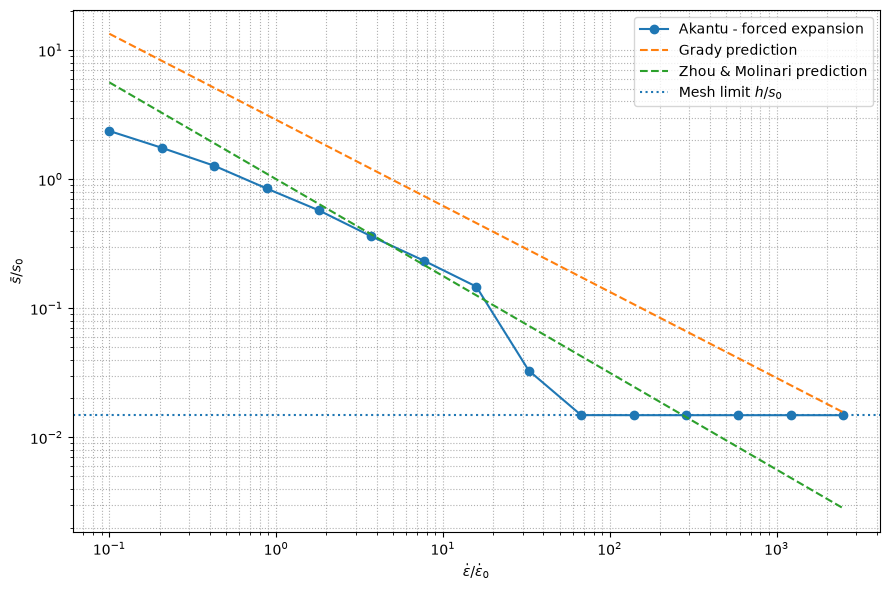

In [17]:
epsdot_hat_grady = np.logspace(
    np.log10(df_rate["epsdot_hat"].min()),
    np.log10(df_rate["epsdot_hat"].max()),
    300,
)

s_hat_grady = (24.0 / epsdot_hat_grady**2)**(1.0 / 3.0)
s_hat_zmr = 1.0 / epsdot_hat_grady**(3.0/4.0)
# Numerical resolution limit
h = 2.0 * L / base_params["number_elements"]
s_hat_mesh = h / s0

print("h =", h, "m")
print("Mesh resolution limit =", s_hat_mesh)

plt.figure(figsize=(9, 6))

plt.loglog(df_rate["epsdot_hat"], df_rate["s_hat"], "o-",
           label="Akantu - forced expansion")

plt.loglog(epsdot_hat_grady, s_hat_grady, "--",
           label="Grady prediction")
plt.loglog(epsdot_hat_grady, s_hat_zmr, "--",
           label="Zhou & Molinari prediction")

plt.axhline(s_hat_mesh, linestyle=":",
            label=r"Mesh limit $h/s_0$")

plt.xlabel(r"$\dot{\varepsilon}/\dot{\varepsilon}_0$")
plt.ylabel(r"$\bar{s}/s_0$")

plt.grid(True, which="both", linestyle=":")
plt.legend()
plt.tight_layout()
plt.savefig("data/fragmentation_rate_sweep_50000_elements.png", dpi=300)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
def x(X,k,t):
    return X[0] + k * t * X[1]
def y(X,k,t):
    return X[1] + k * t * X[0]


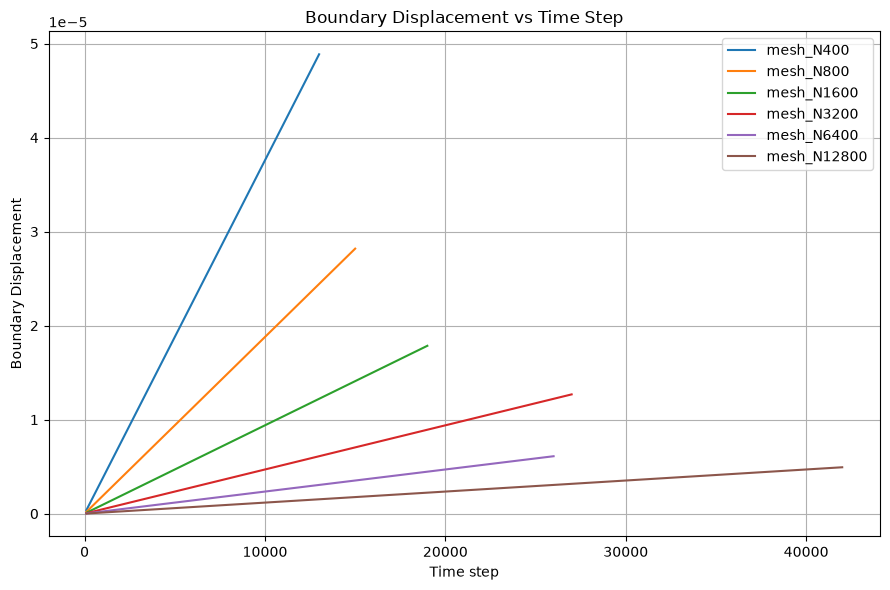

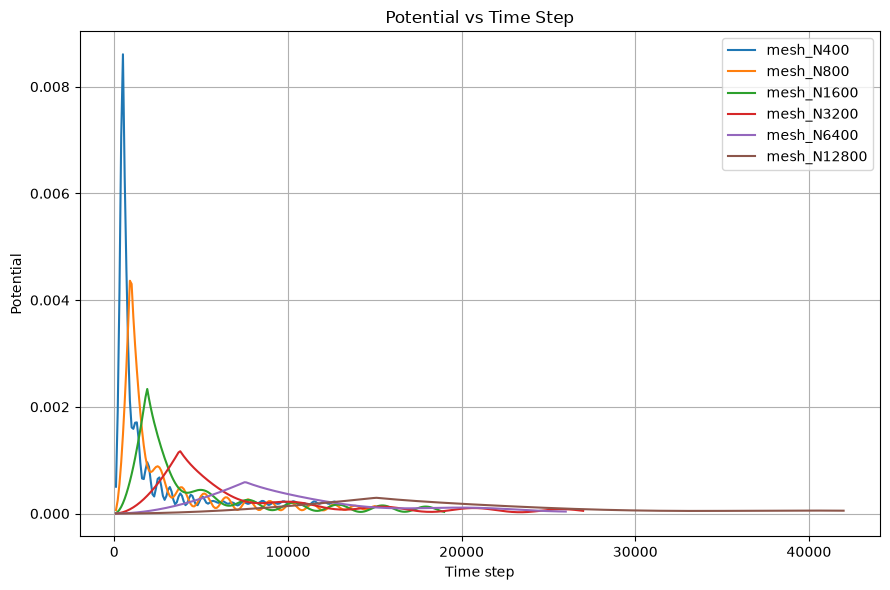

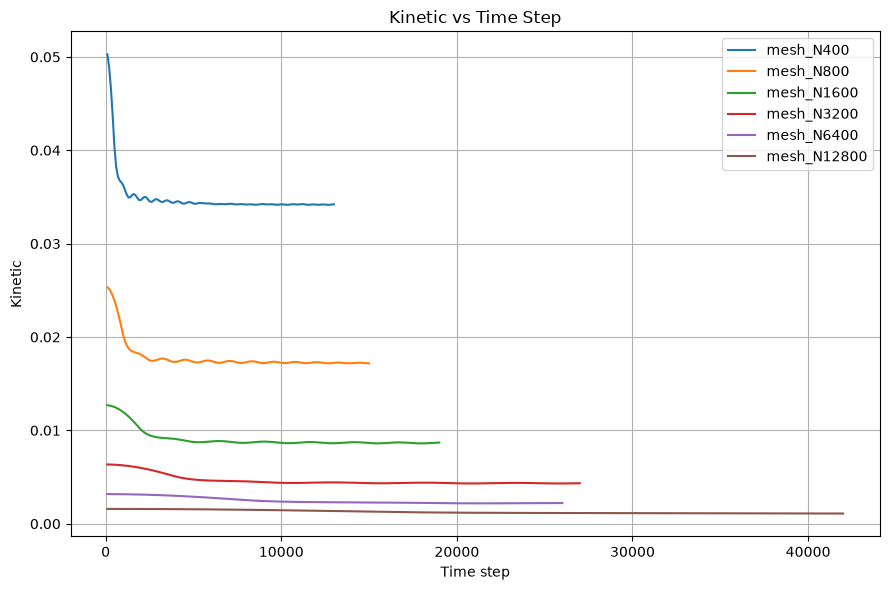

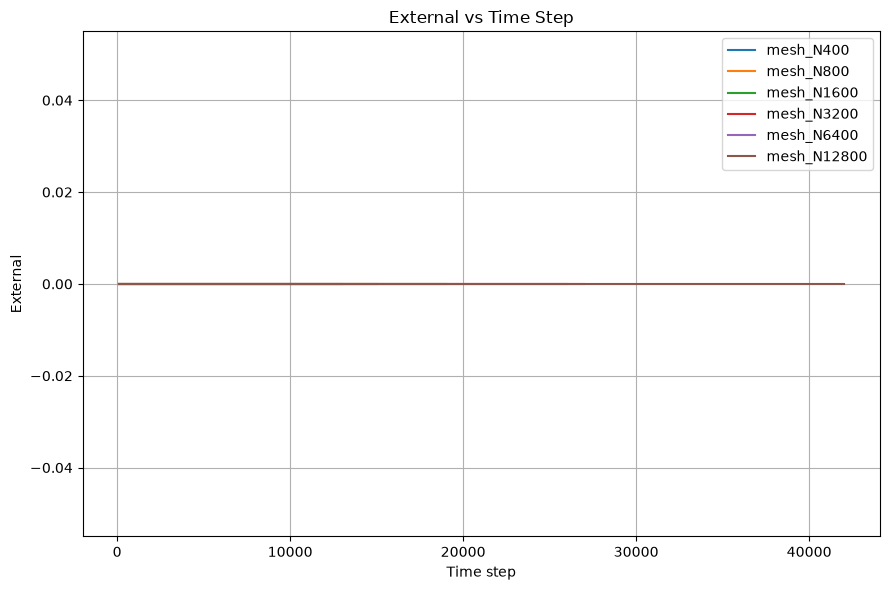

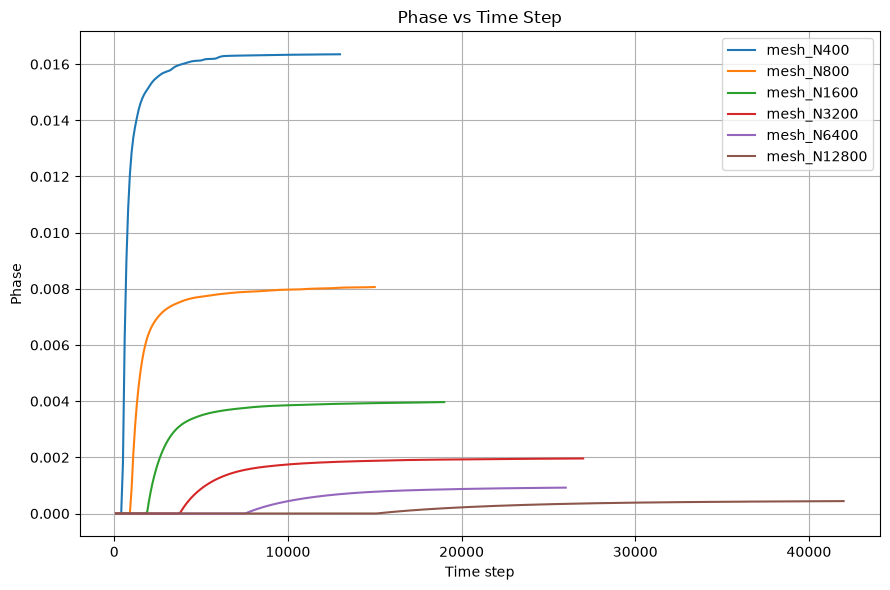

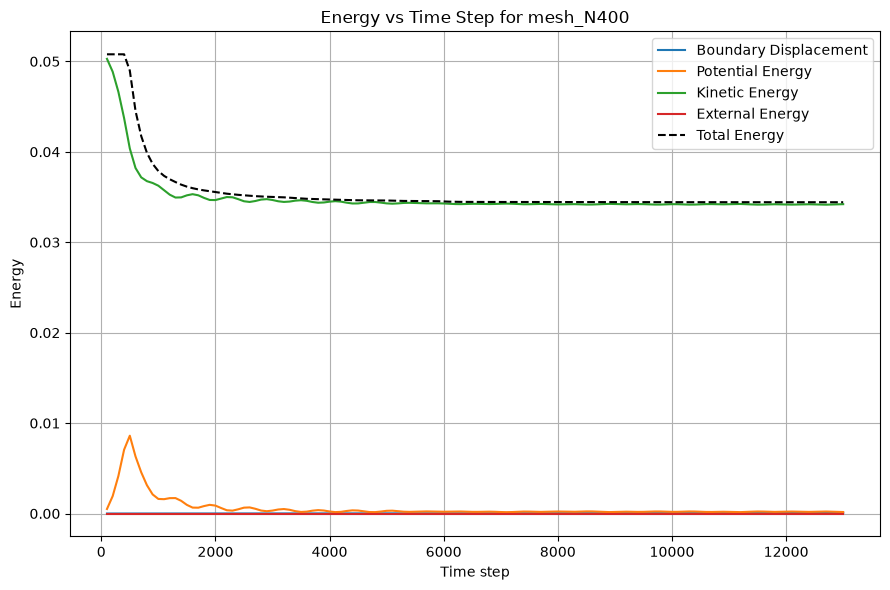

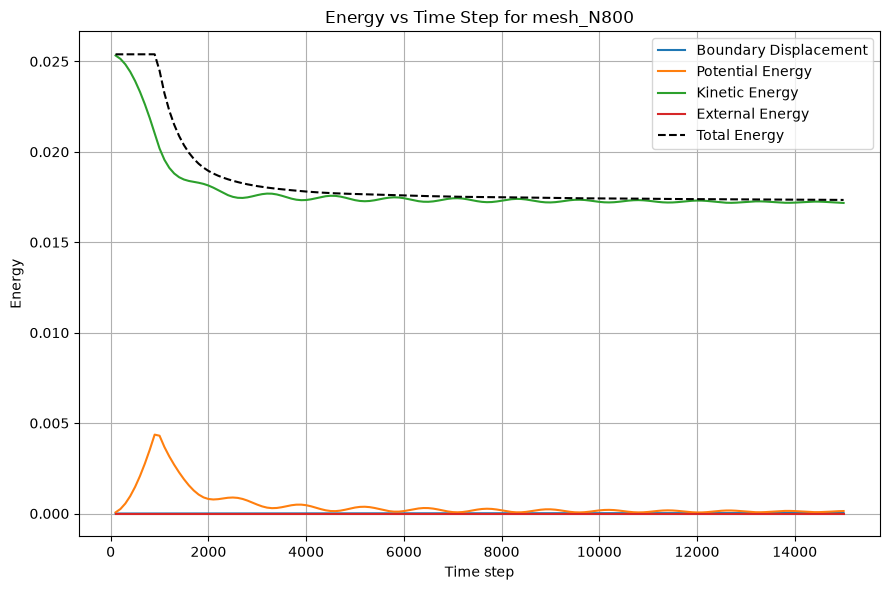

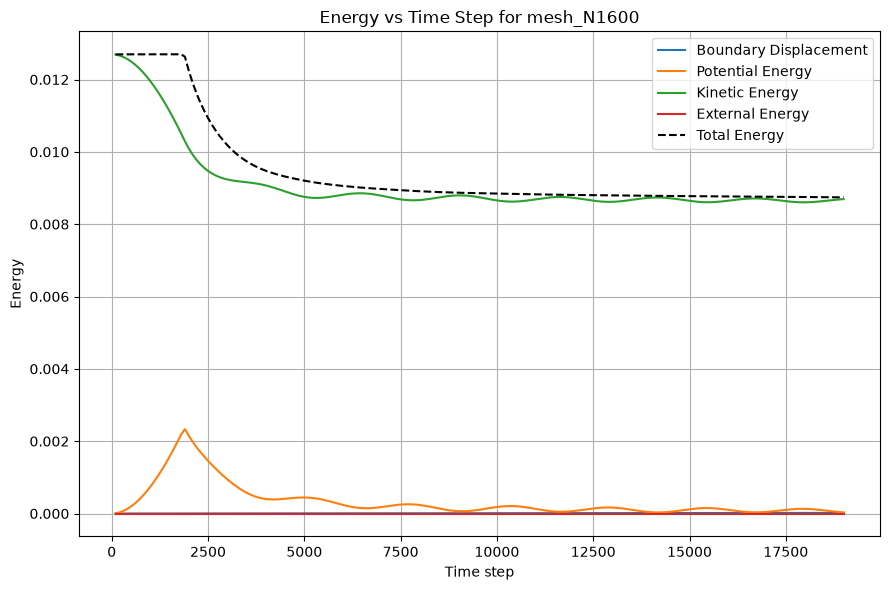

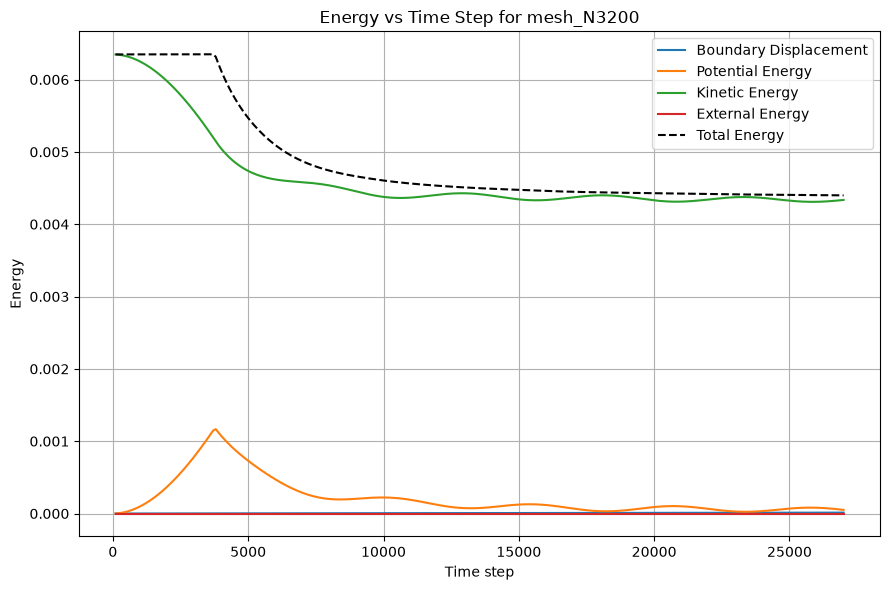

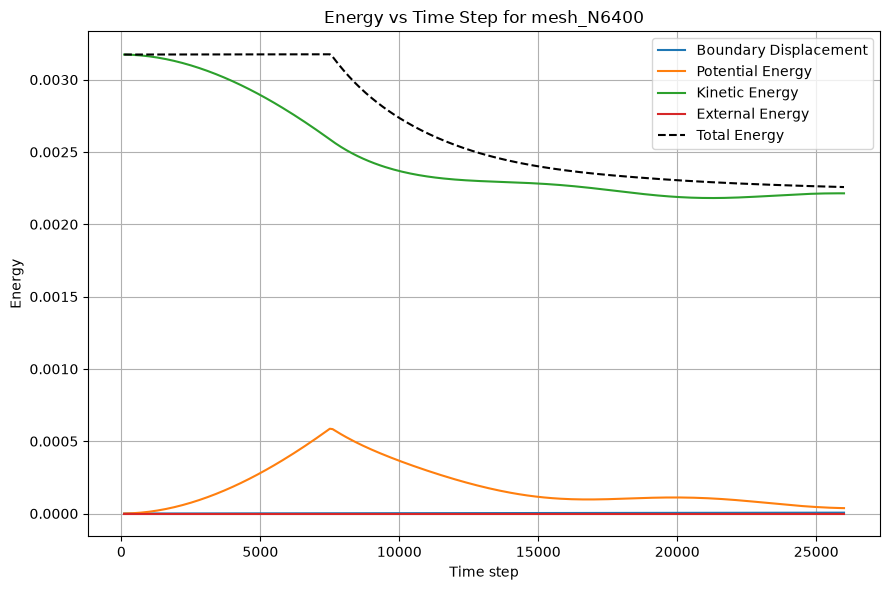

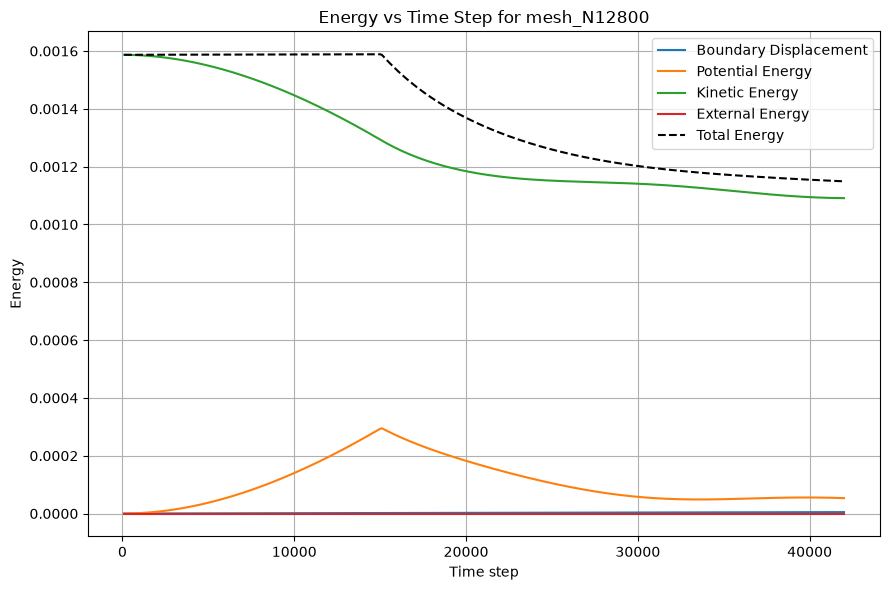

In [1]:
import numpy as np
import matplotlib.pyplot as plt

files = [
    "data/PF/mesh_N400/energies_pf.out",
    "data/PF/mesh_N800/energies_pf.out",
    "data/PF/mesh_N1600/energies_pf.out",
    "data/PF/mesh_N3200/energies_pf.out",
    "data/PF/mesh_N6400/energies_pf.out",
    "data/PF/mesh_N12800/energies_pf.out",
]

quantities = ["boundary_displacement", "potential", "kinetic", "external", "phase"]

for quant in quantities:
    plt.figure(figsize=(9, 6))

    for file in files:
        data = np.loadtxt(file, skiprows=1)

        step = data[:, 0]
        quantity = data[:, 2 + quantities.index(quant)]

        plt.plot(step, quantity, label=file.split("/")[-2])

    plt.xlabel("Time step")
    plt.ylabel(quant.replace("_", " ").title())
    plt.title(f"{quant.replace('_', ' ').title()} vs Time Step")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

for file in files:
    data = np.loadtxt(file, skiprows=1)
    step = data[:, 0]
    boundary_displacement = data[:, 2]
    potential_energy = data[:, 3]
    kinetic_energy = data[:, 4]
    external_energy = data[:, 5]
    total_energy = data[:, 2] + data[:, 3] + data[:, 4] + data[:, 5]
    plt.figure(figsize=(9, 6))
    plt.plot(step, boundary_displacement, label="Boundary Displacement")
    plt.plot(step, potential_energy, label="Potential Energy")
    plt.plot(step, kinetic_energy, label="Kinetic Energy")
    plt.plot(step, external_energy, label="External Energy")
    plt.plot(step, total_energy, label="Total Energy", linestyle="--", color="black")
    plt.xlabel("Time step")
    plt.ylabel("Energy")
    plt.title(f"Energy vs Time Step for {file.split('/')[-2]}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


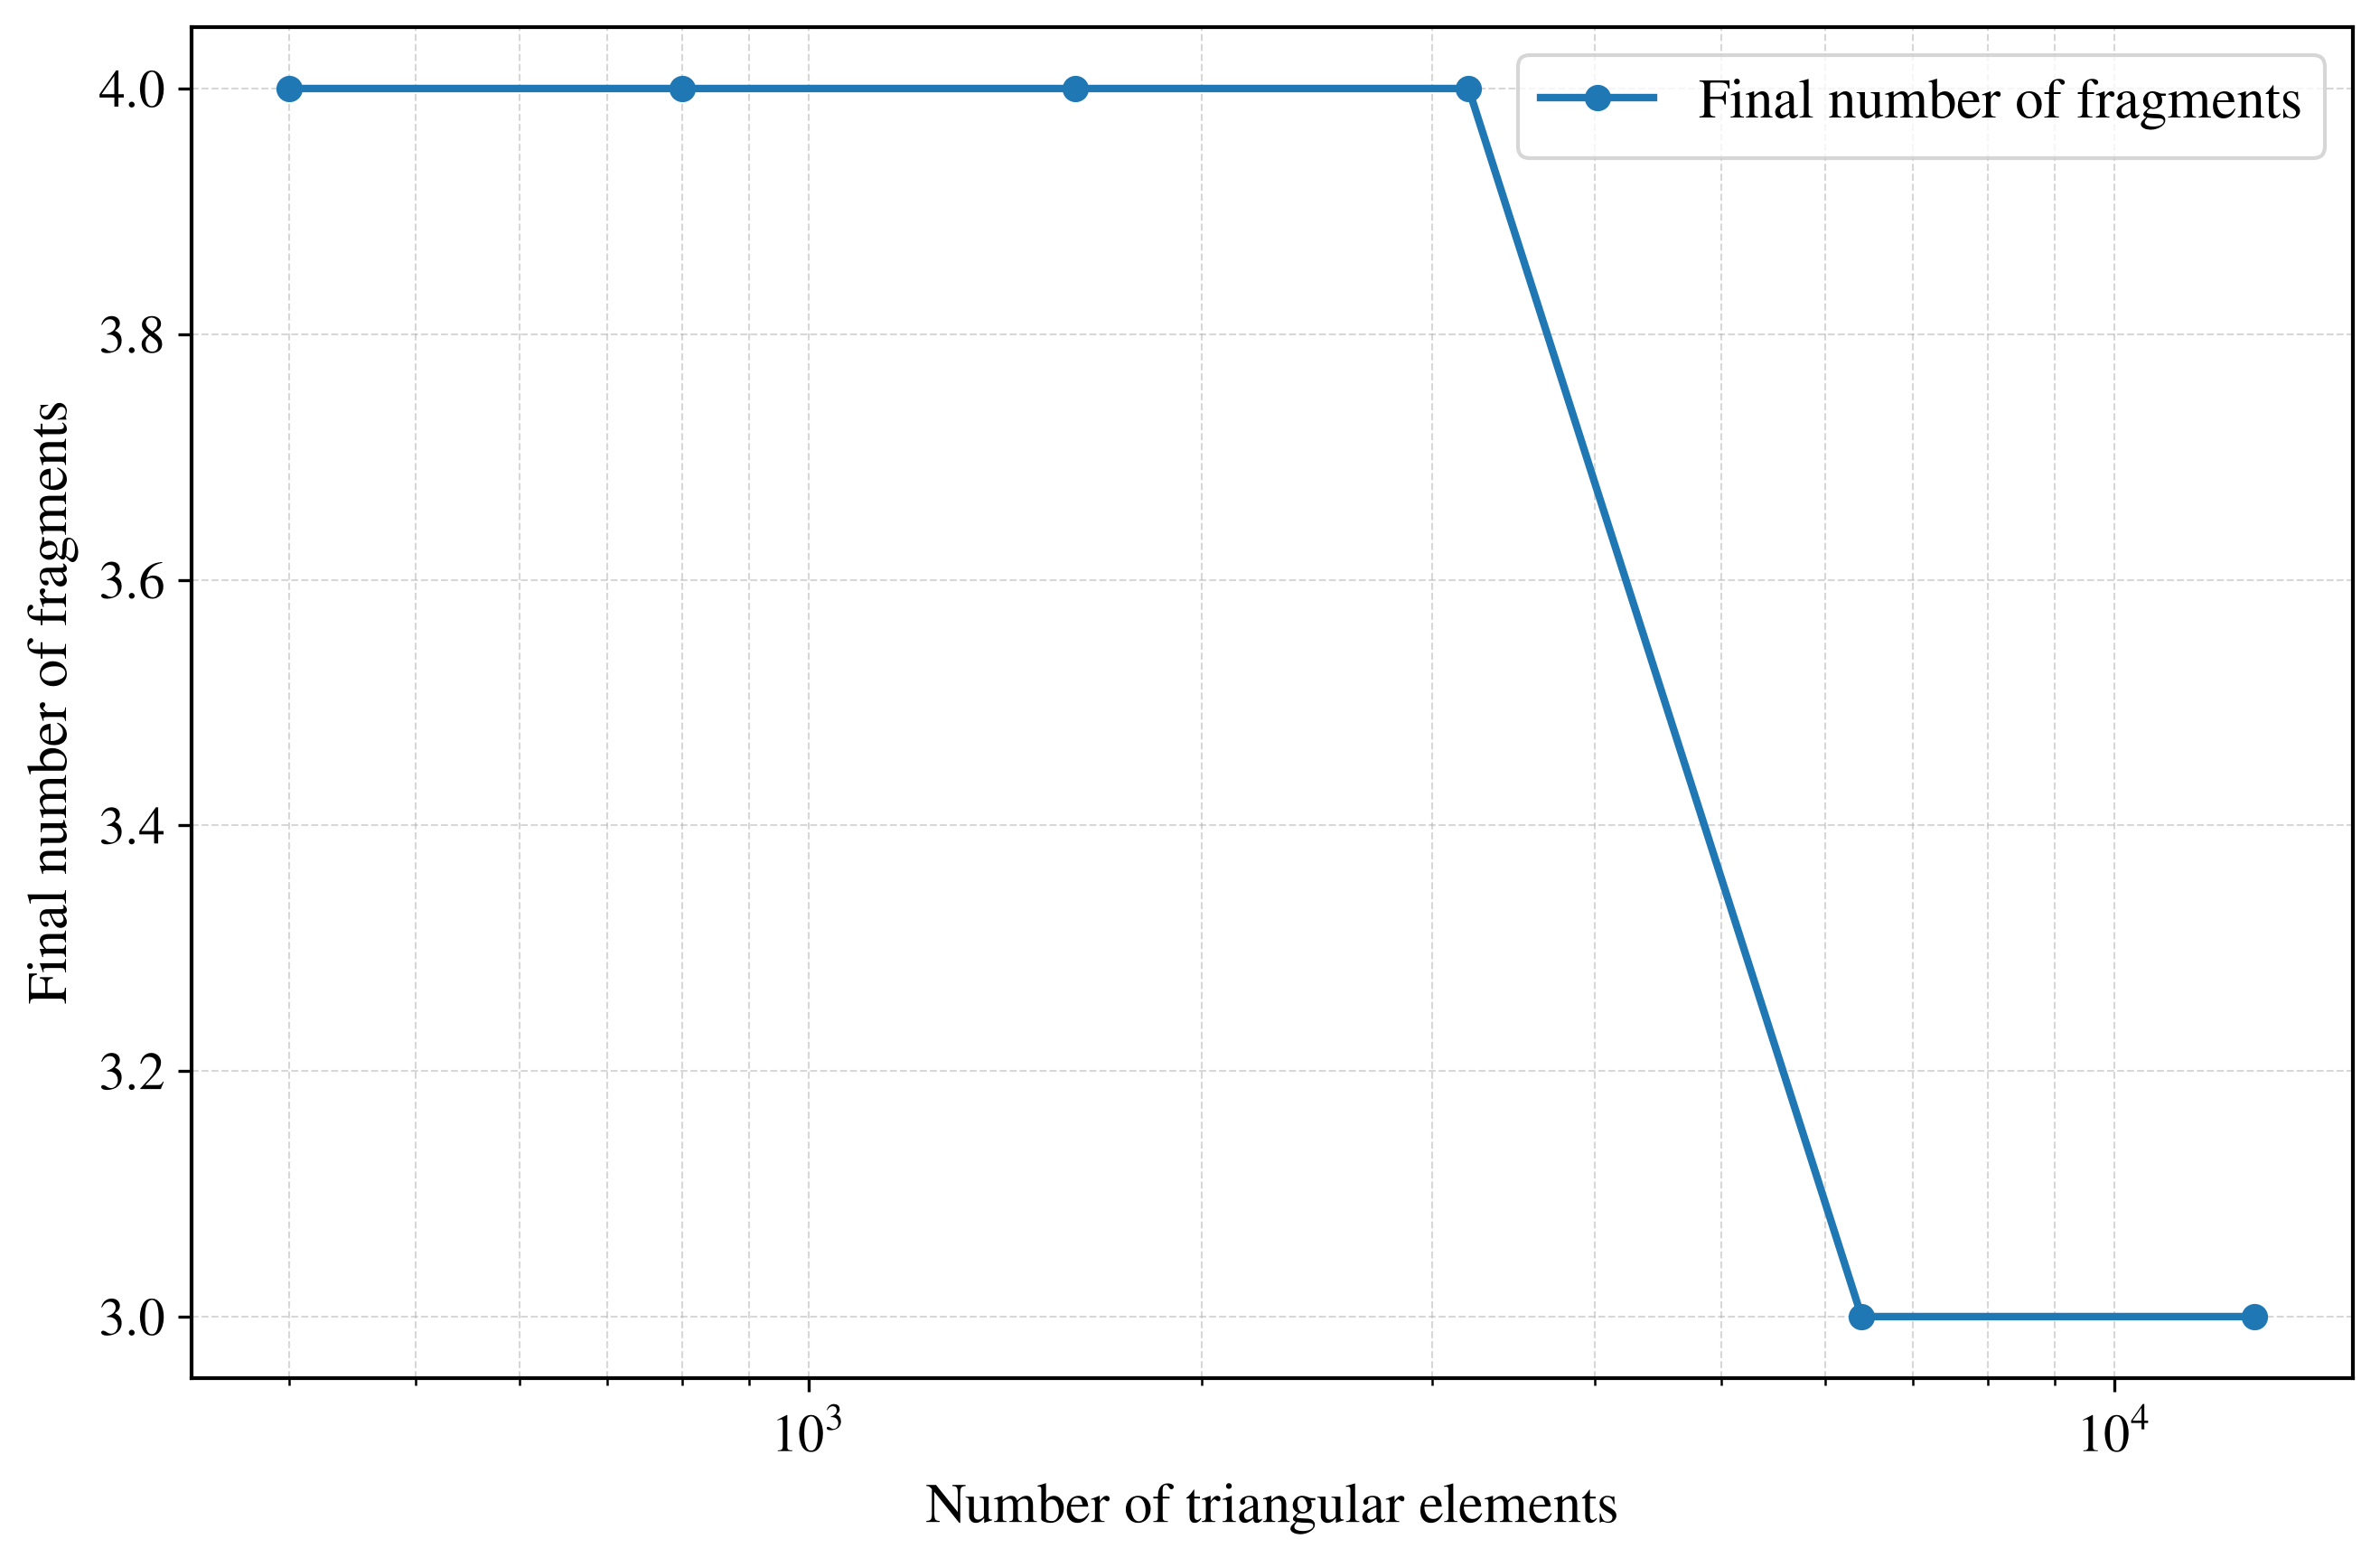

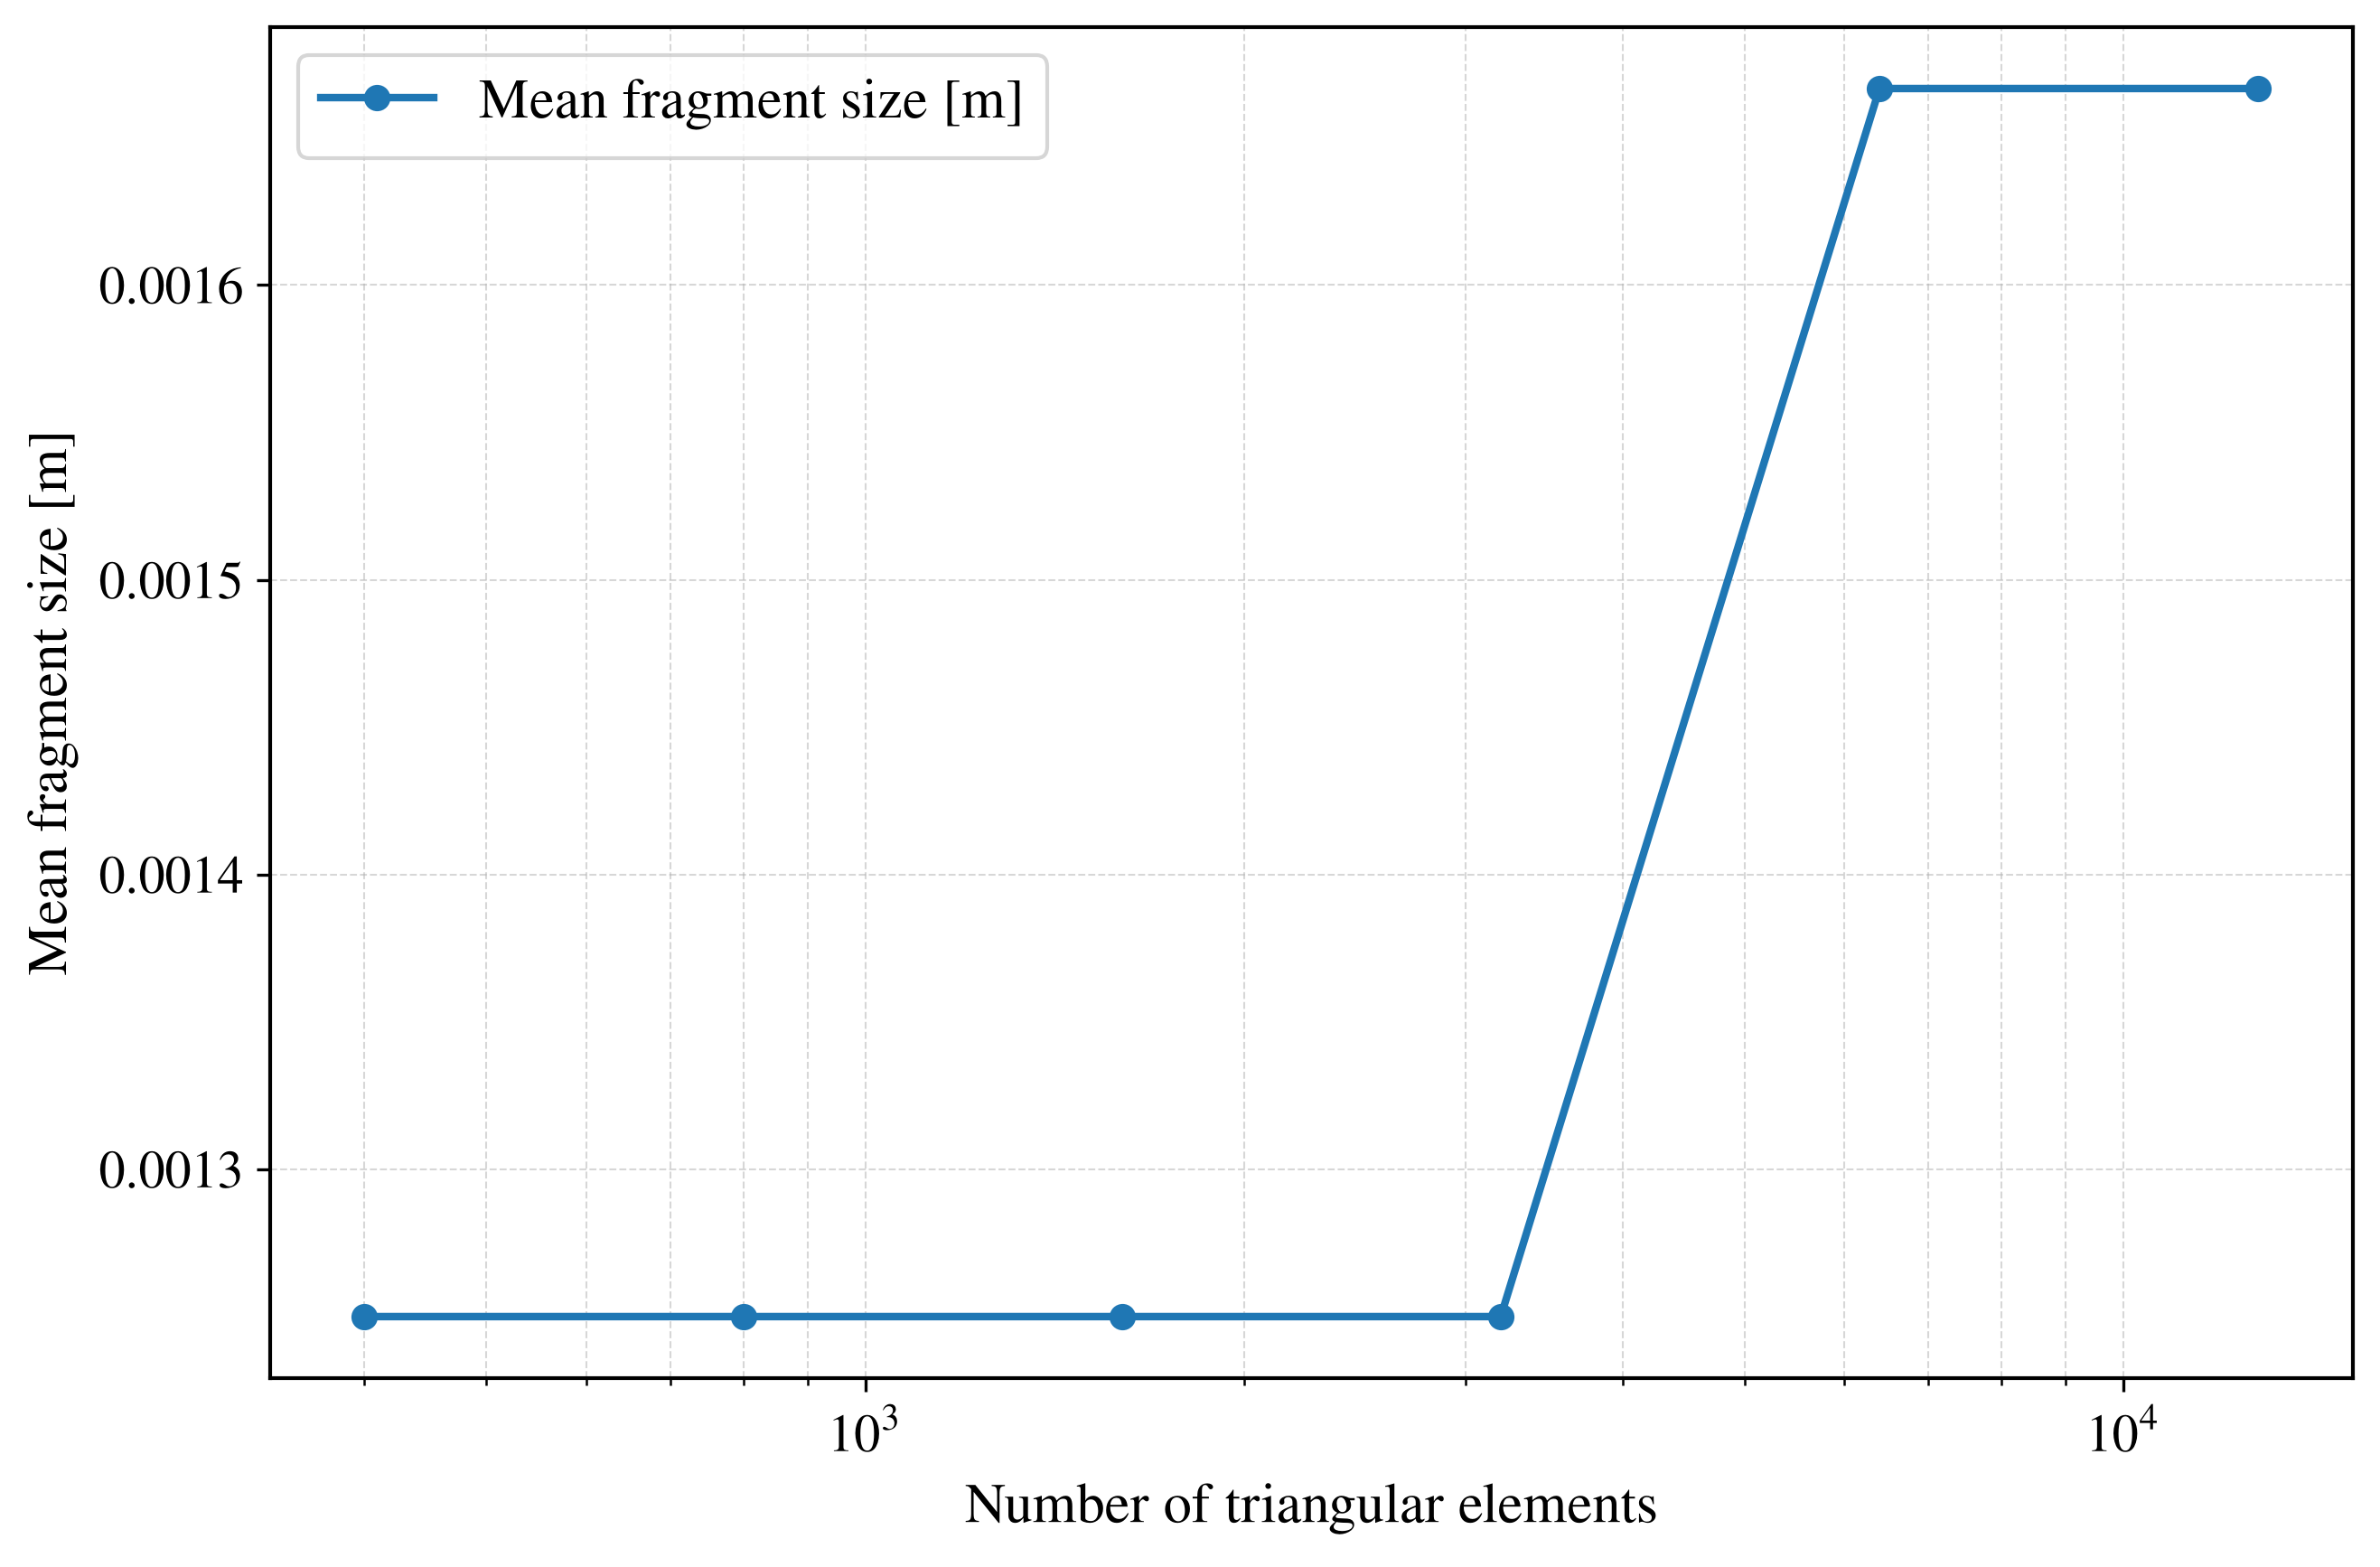

In [11]:
# number of fragments
files = [
    "data/PF/mesh_N400/fragments_pf.out",
    "data/PF/mesh_N800/fragments_pf.out",
    "data/PF/mesh_N1600/fragments_pf.out",
    "data/PF/mesh_N3200/fragments_pf.out",
    "data/PF/mesh_N6400/fragments_pf.out",
    "data/PF/mesh_N12800/fragments_pf.out",
]
nfragments = []
mean_sizes = []
N = [400, 800, 1600, 3200, 6400, 12800]
for file in files:
    nfragment = np.loadtxt(file, skiprows=1)[0]
    meansize = np.loadtxt(file, skiprows=1)[1]
    nfragments.append(nfragment)
    mean_sizes.append(meansize)

plt.figure(figsize=(9, 6))
plt.plot(N, [n for n in nfragments], "o-", label="Final number of fragments")
plt.xscale("log")
plt.xlabel("Number of triangular elements")
plt.ylabel("Final number of fragments")
plt.grid(which="both", linestyle="--", linewidth=0.5)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
plt.plot(N, [s for s in mean_sizes], "o-", label="Mean fragment size [m]")
plt.xscale("log")
plt.xlabel("Number of triangular elements")
plt.ylabel("Mean fragment size [m]")
plt.grid(which="both", linestyle="--", linewidth=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Presentation with resul and comp

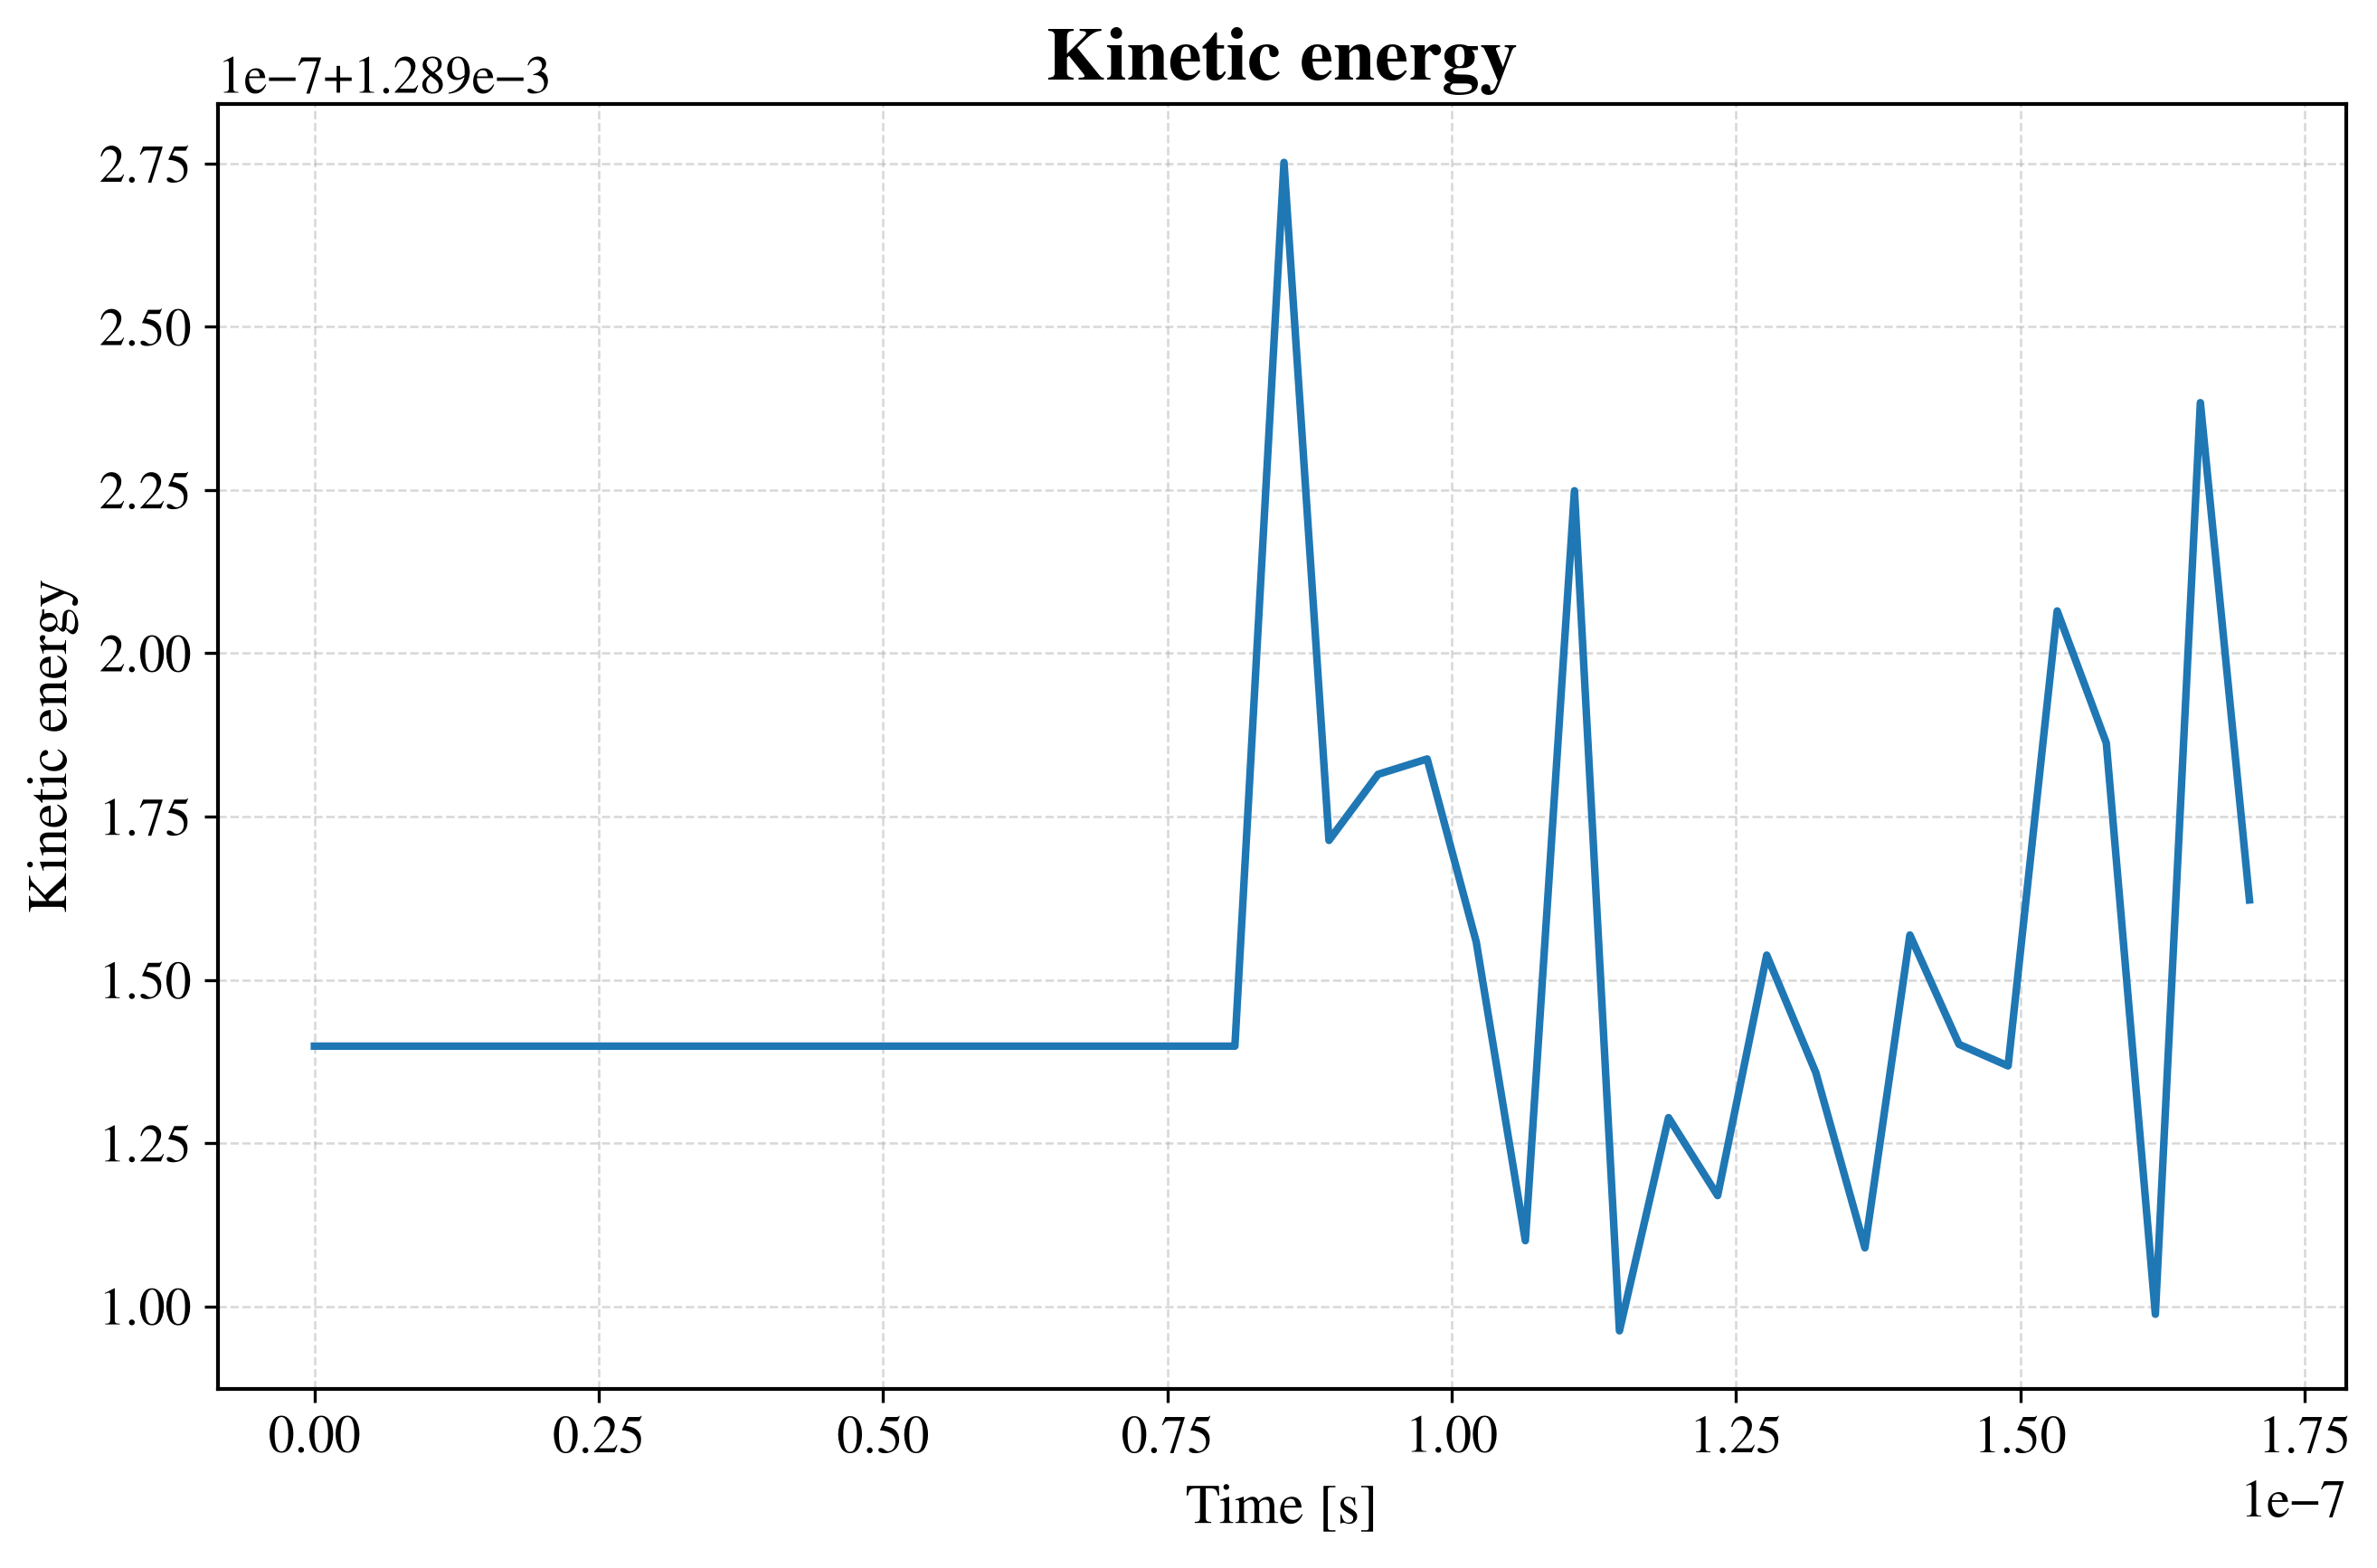

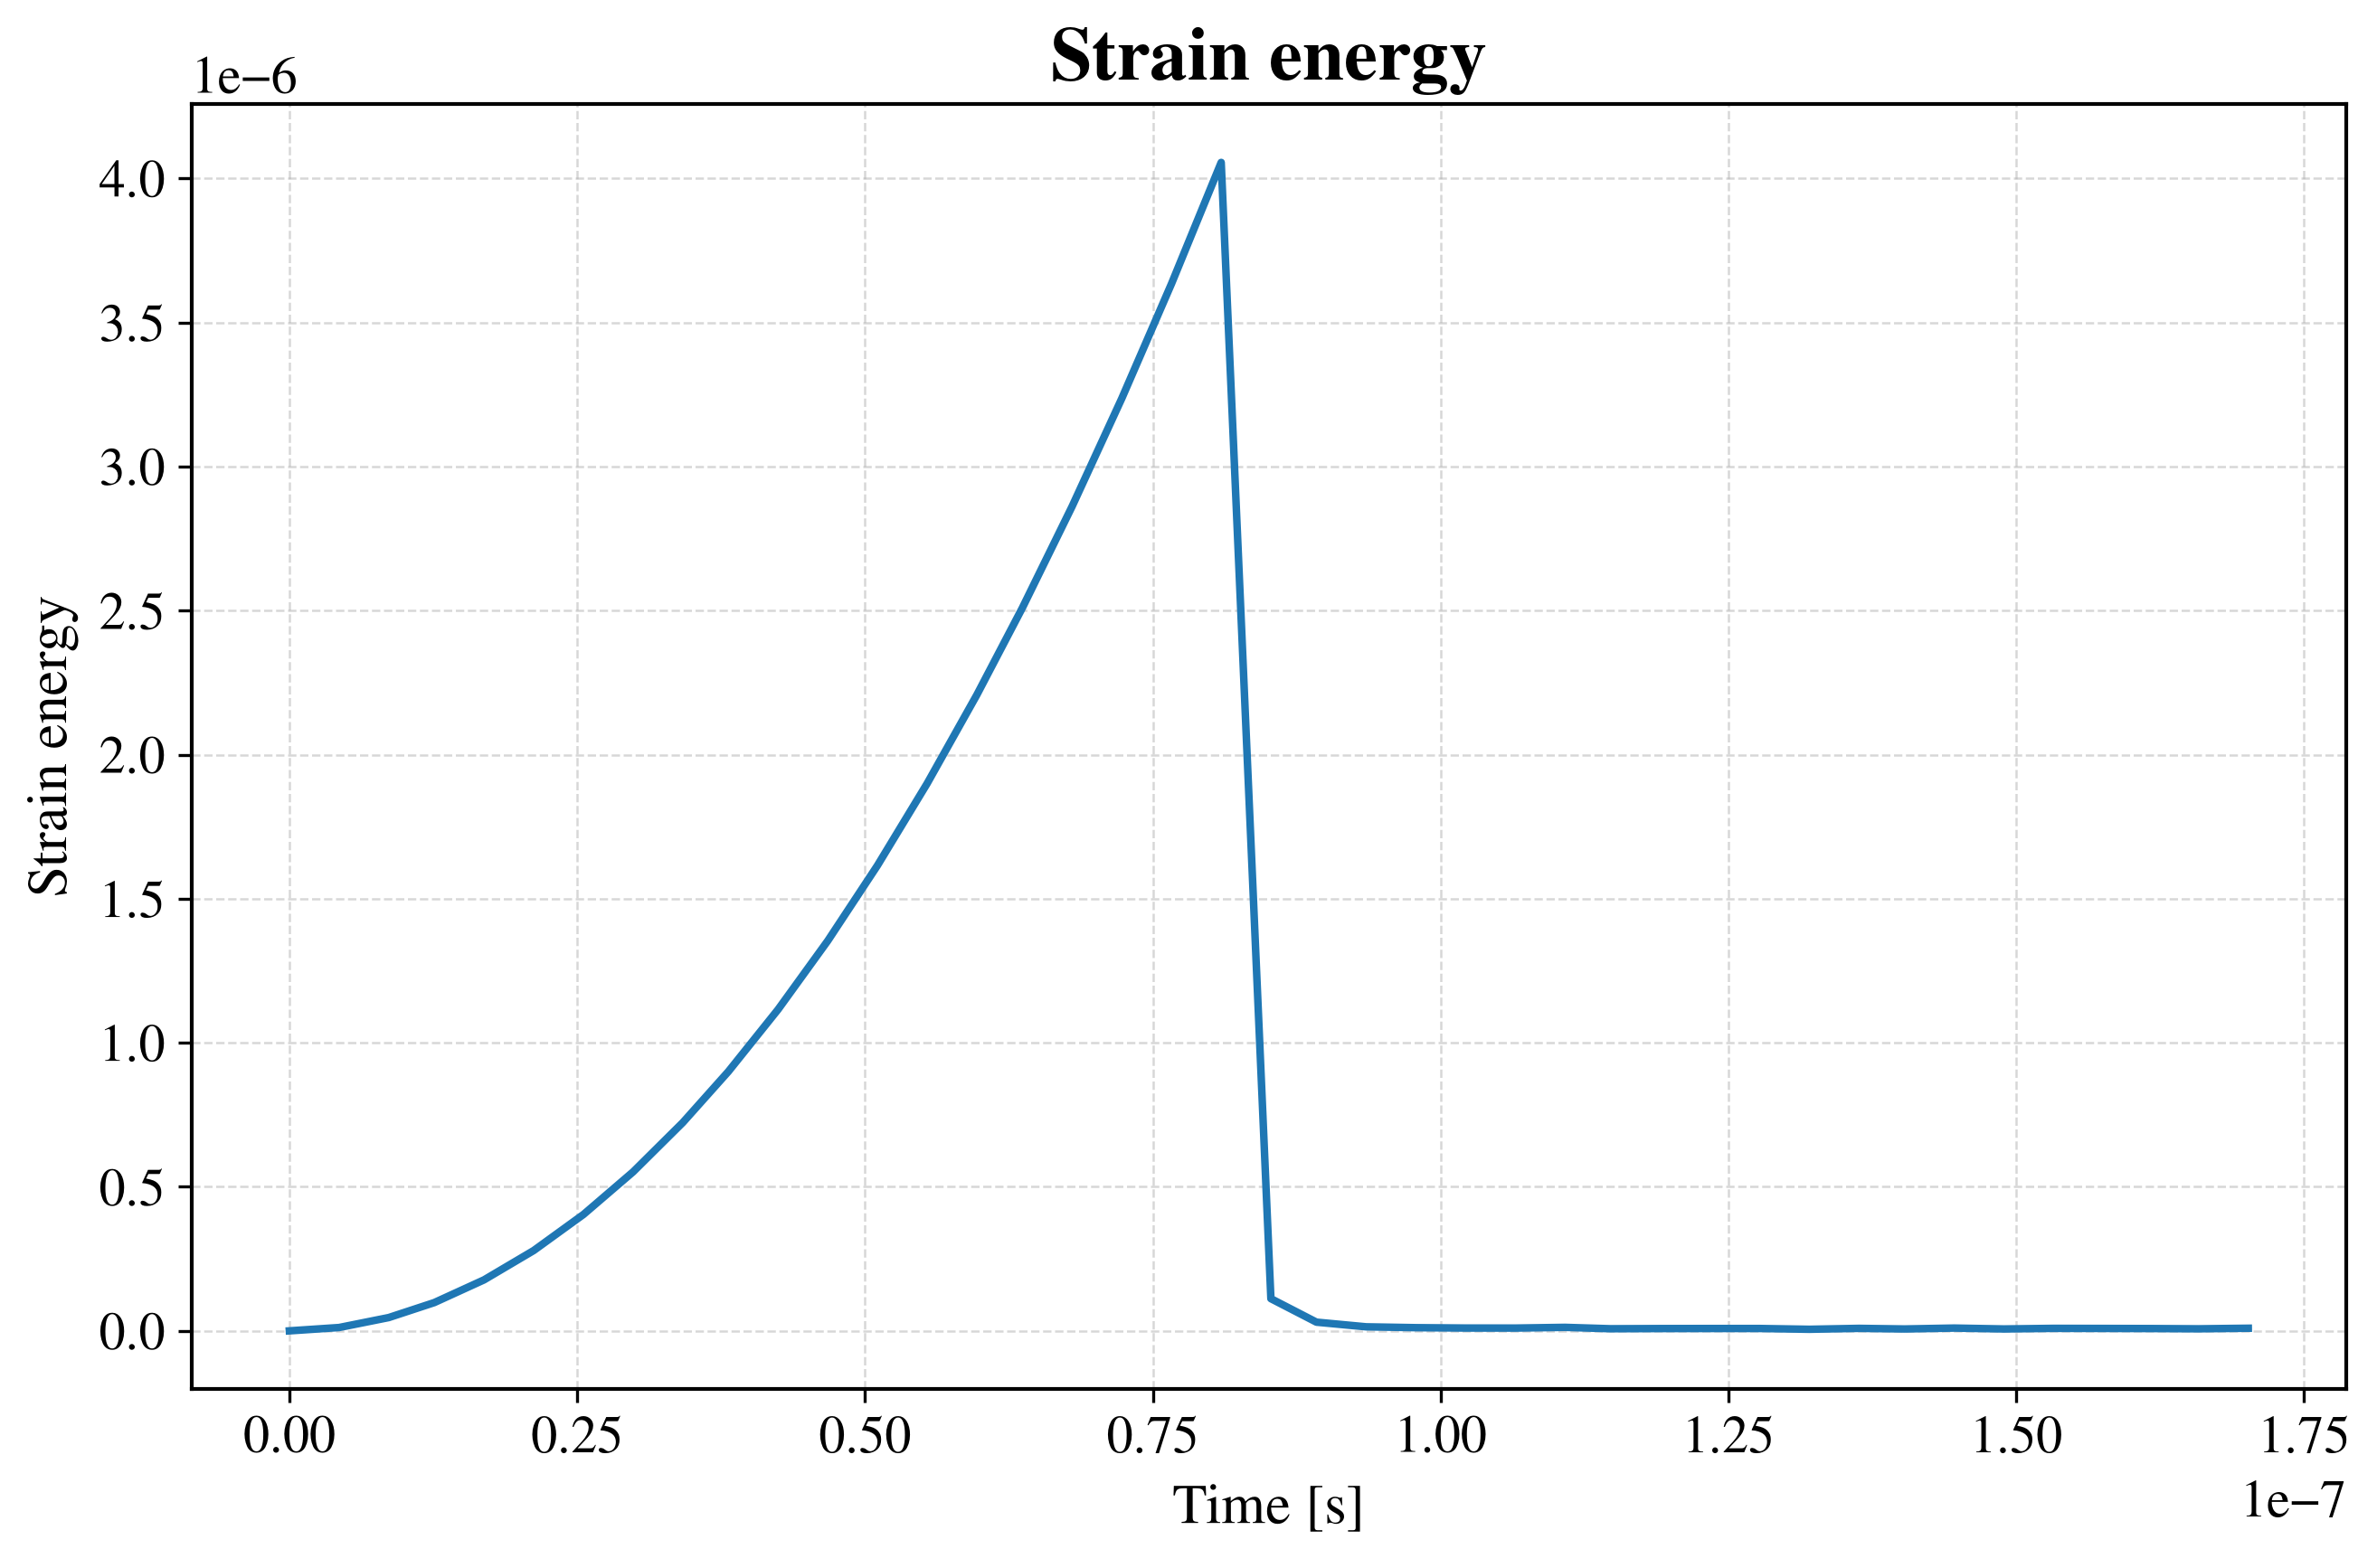

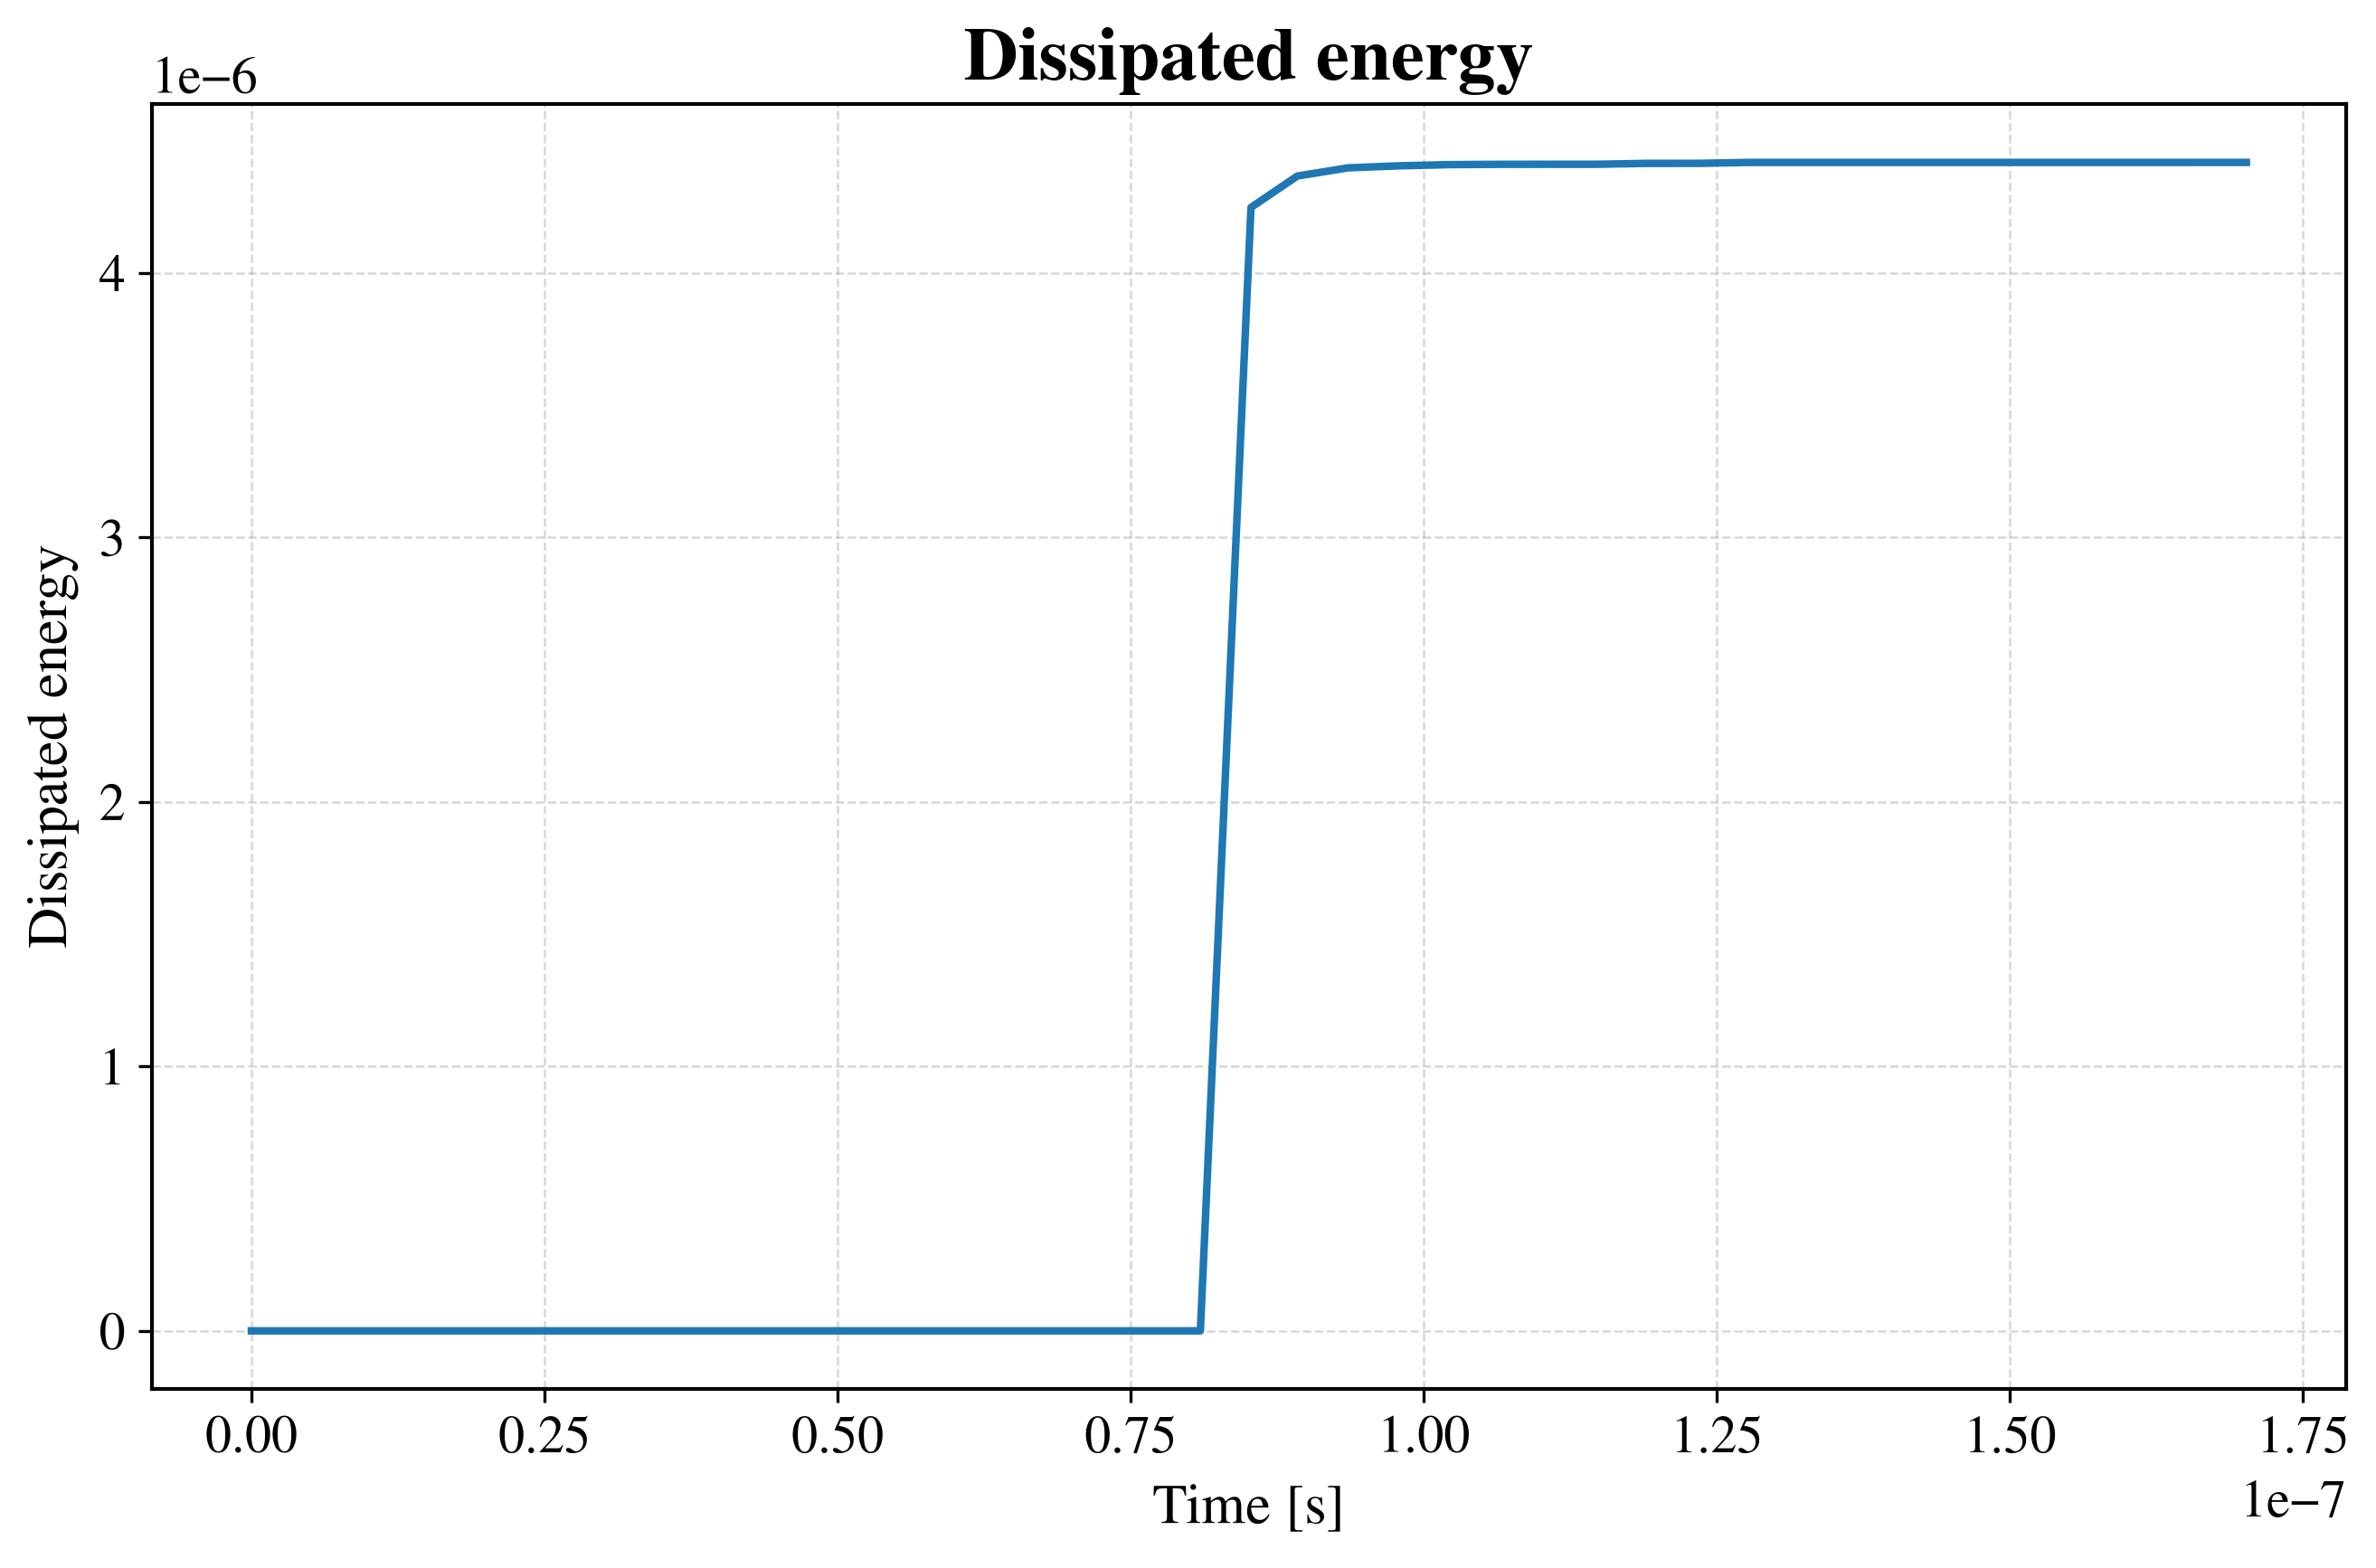

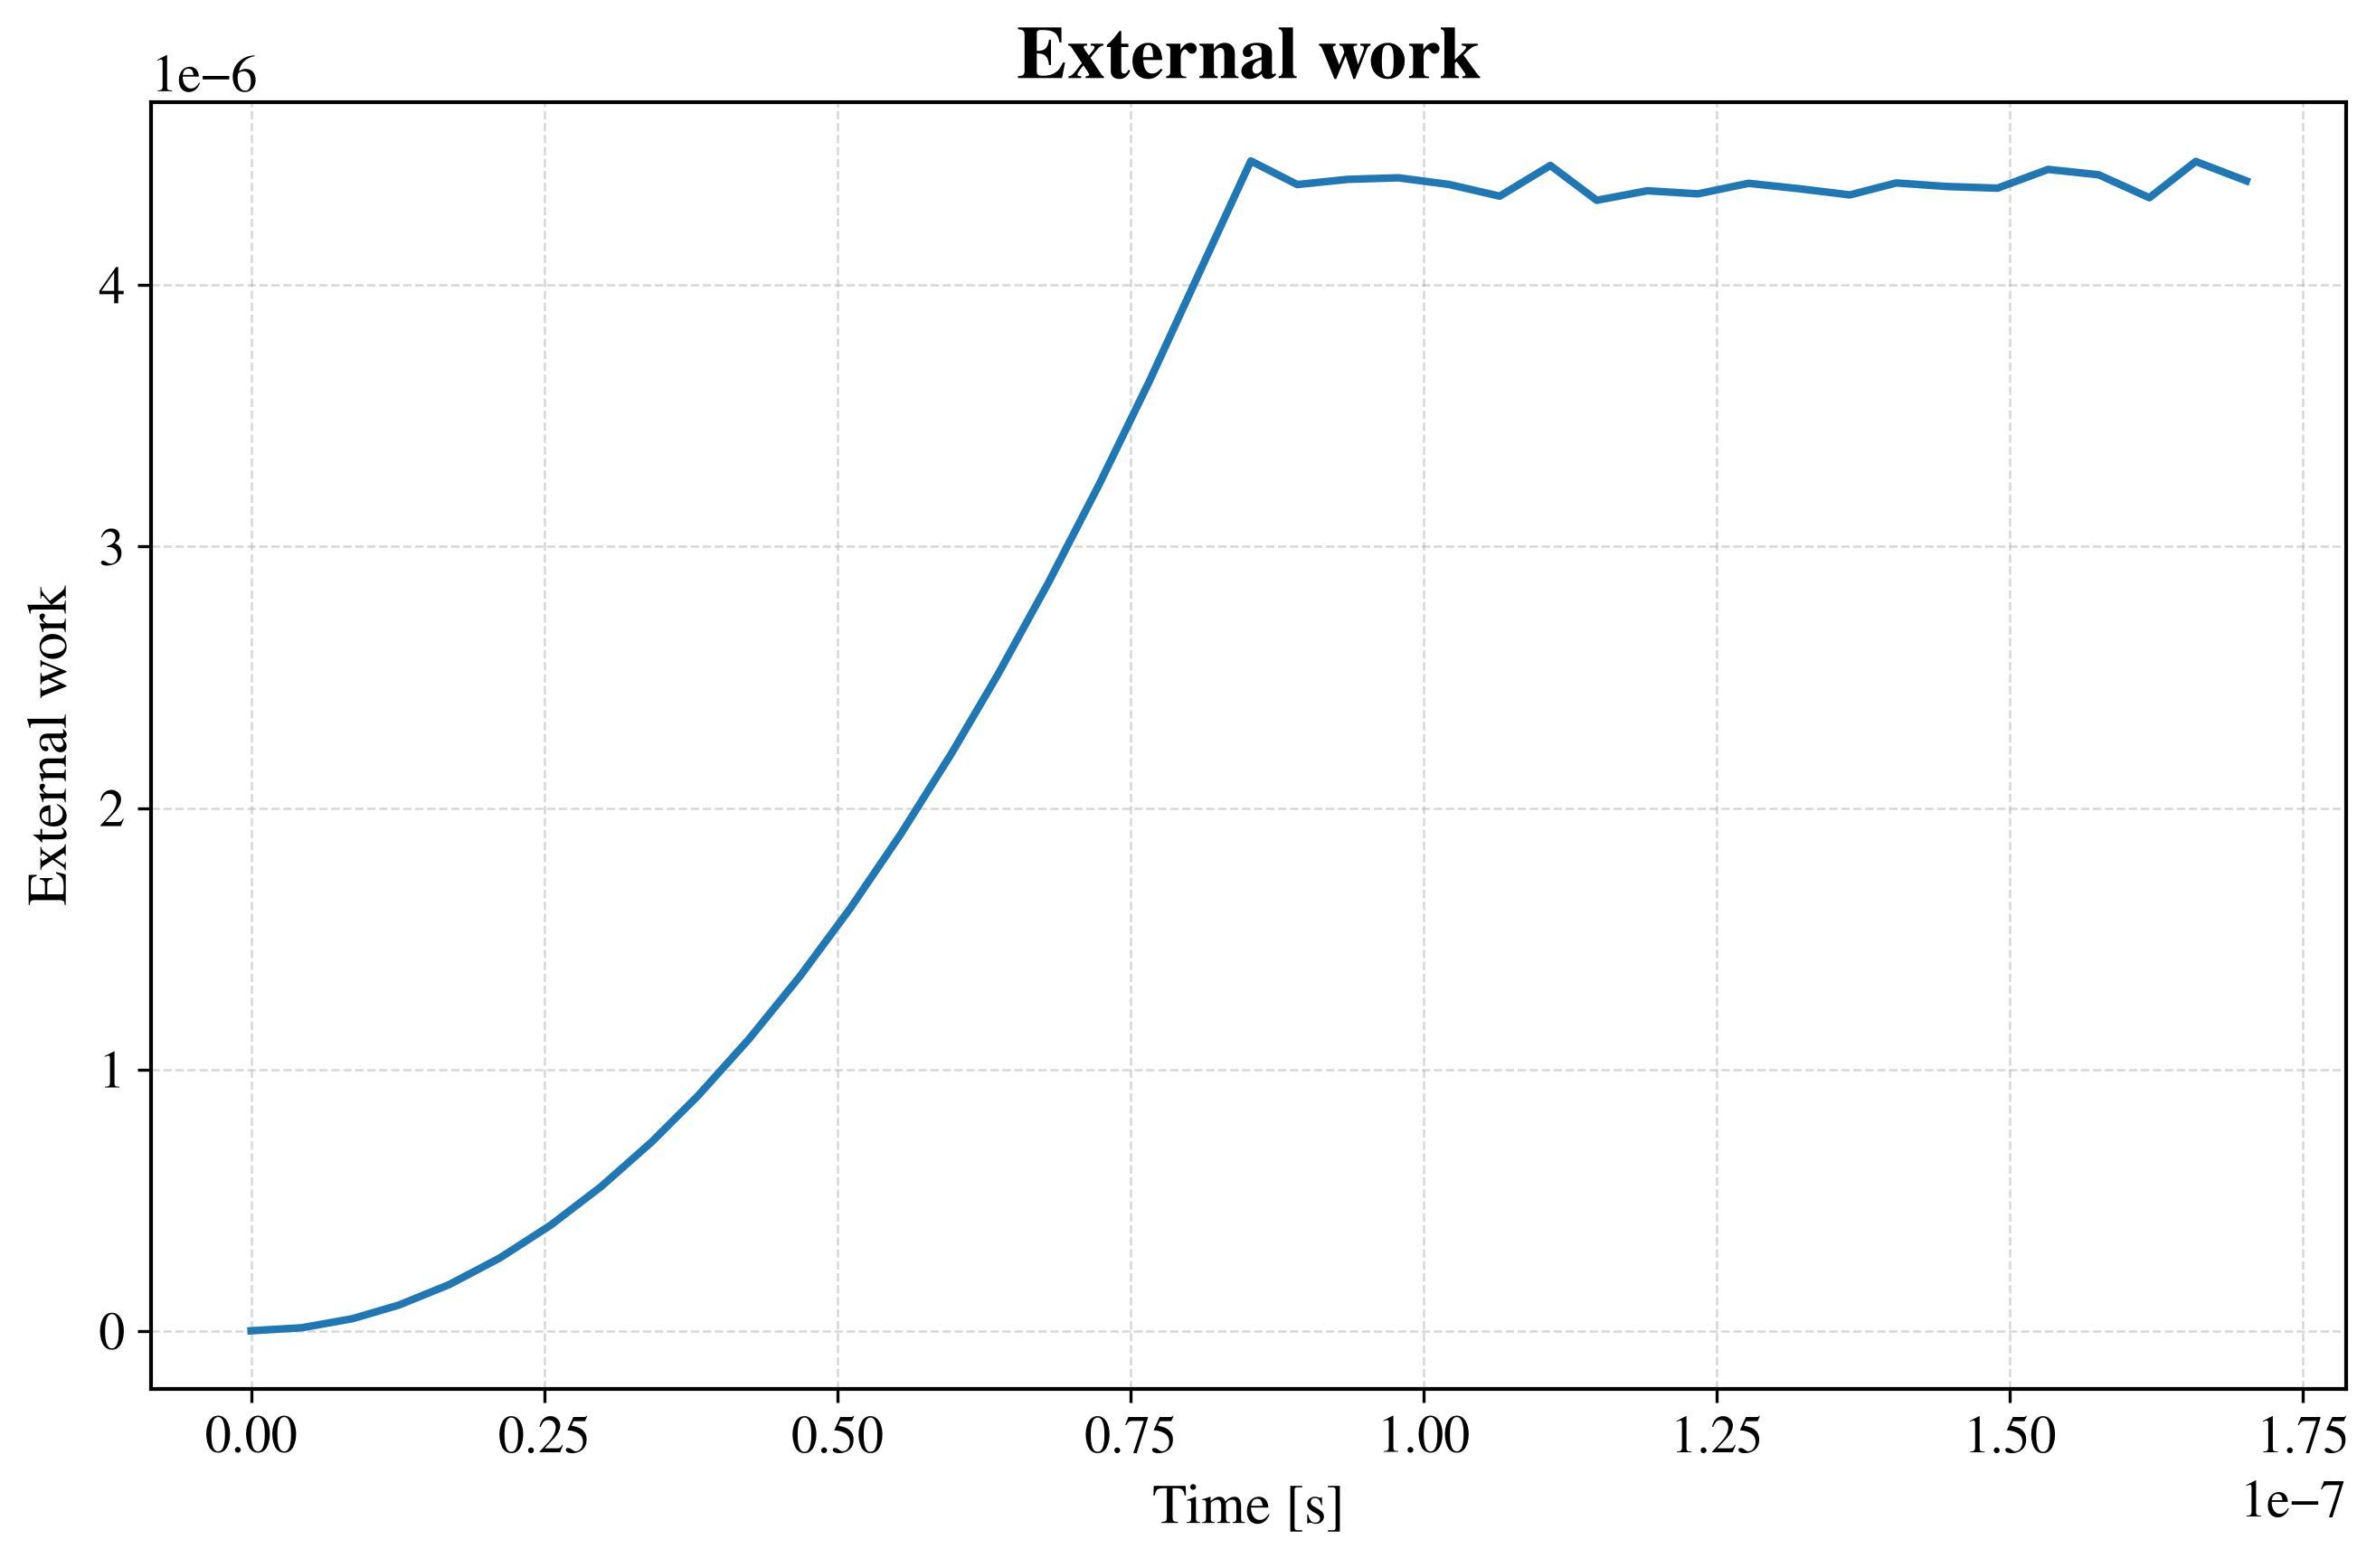

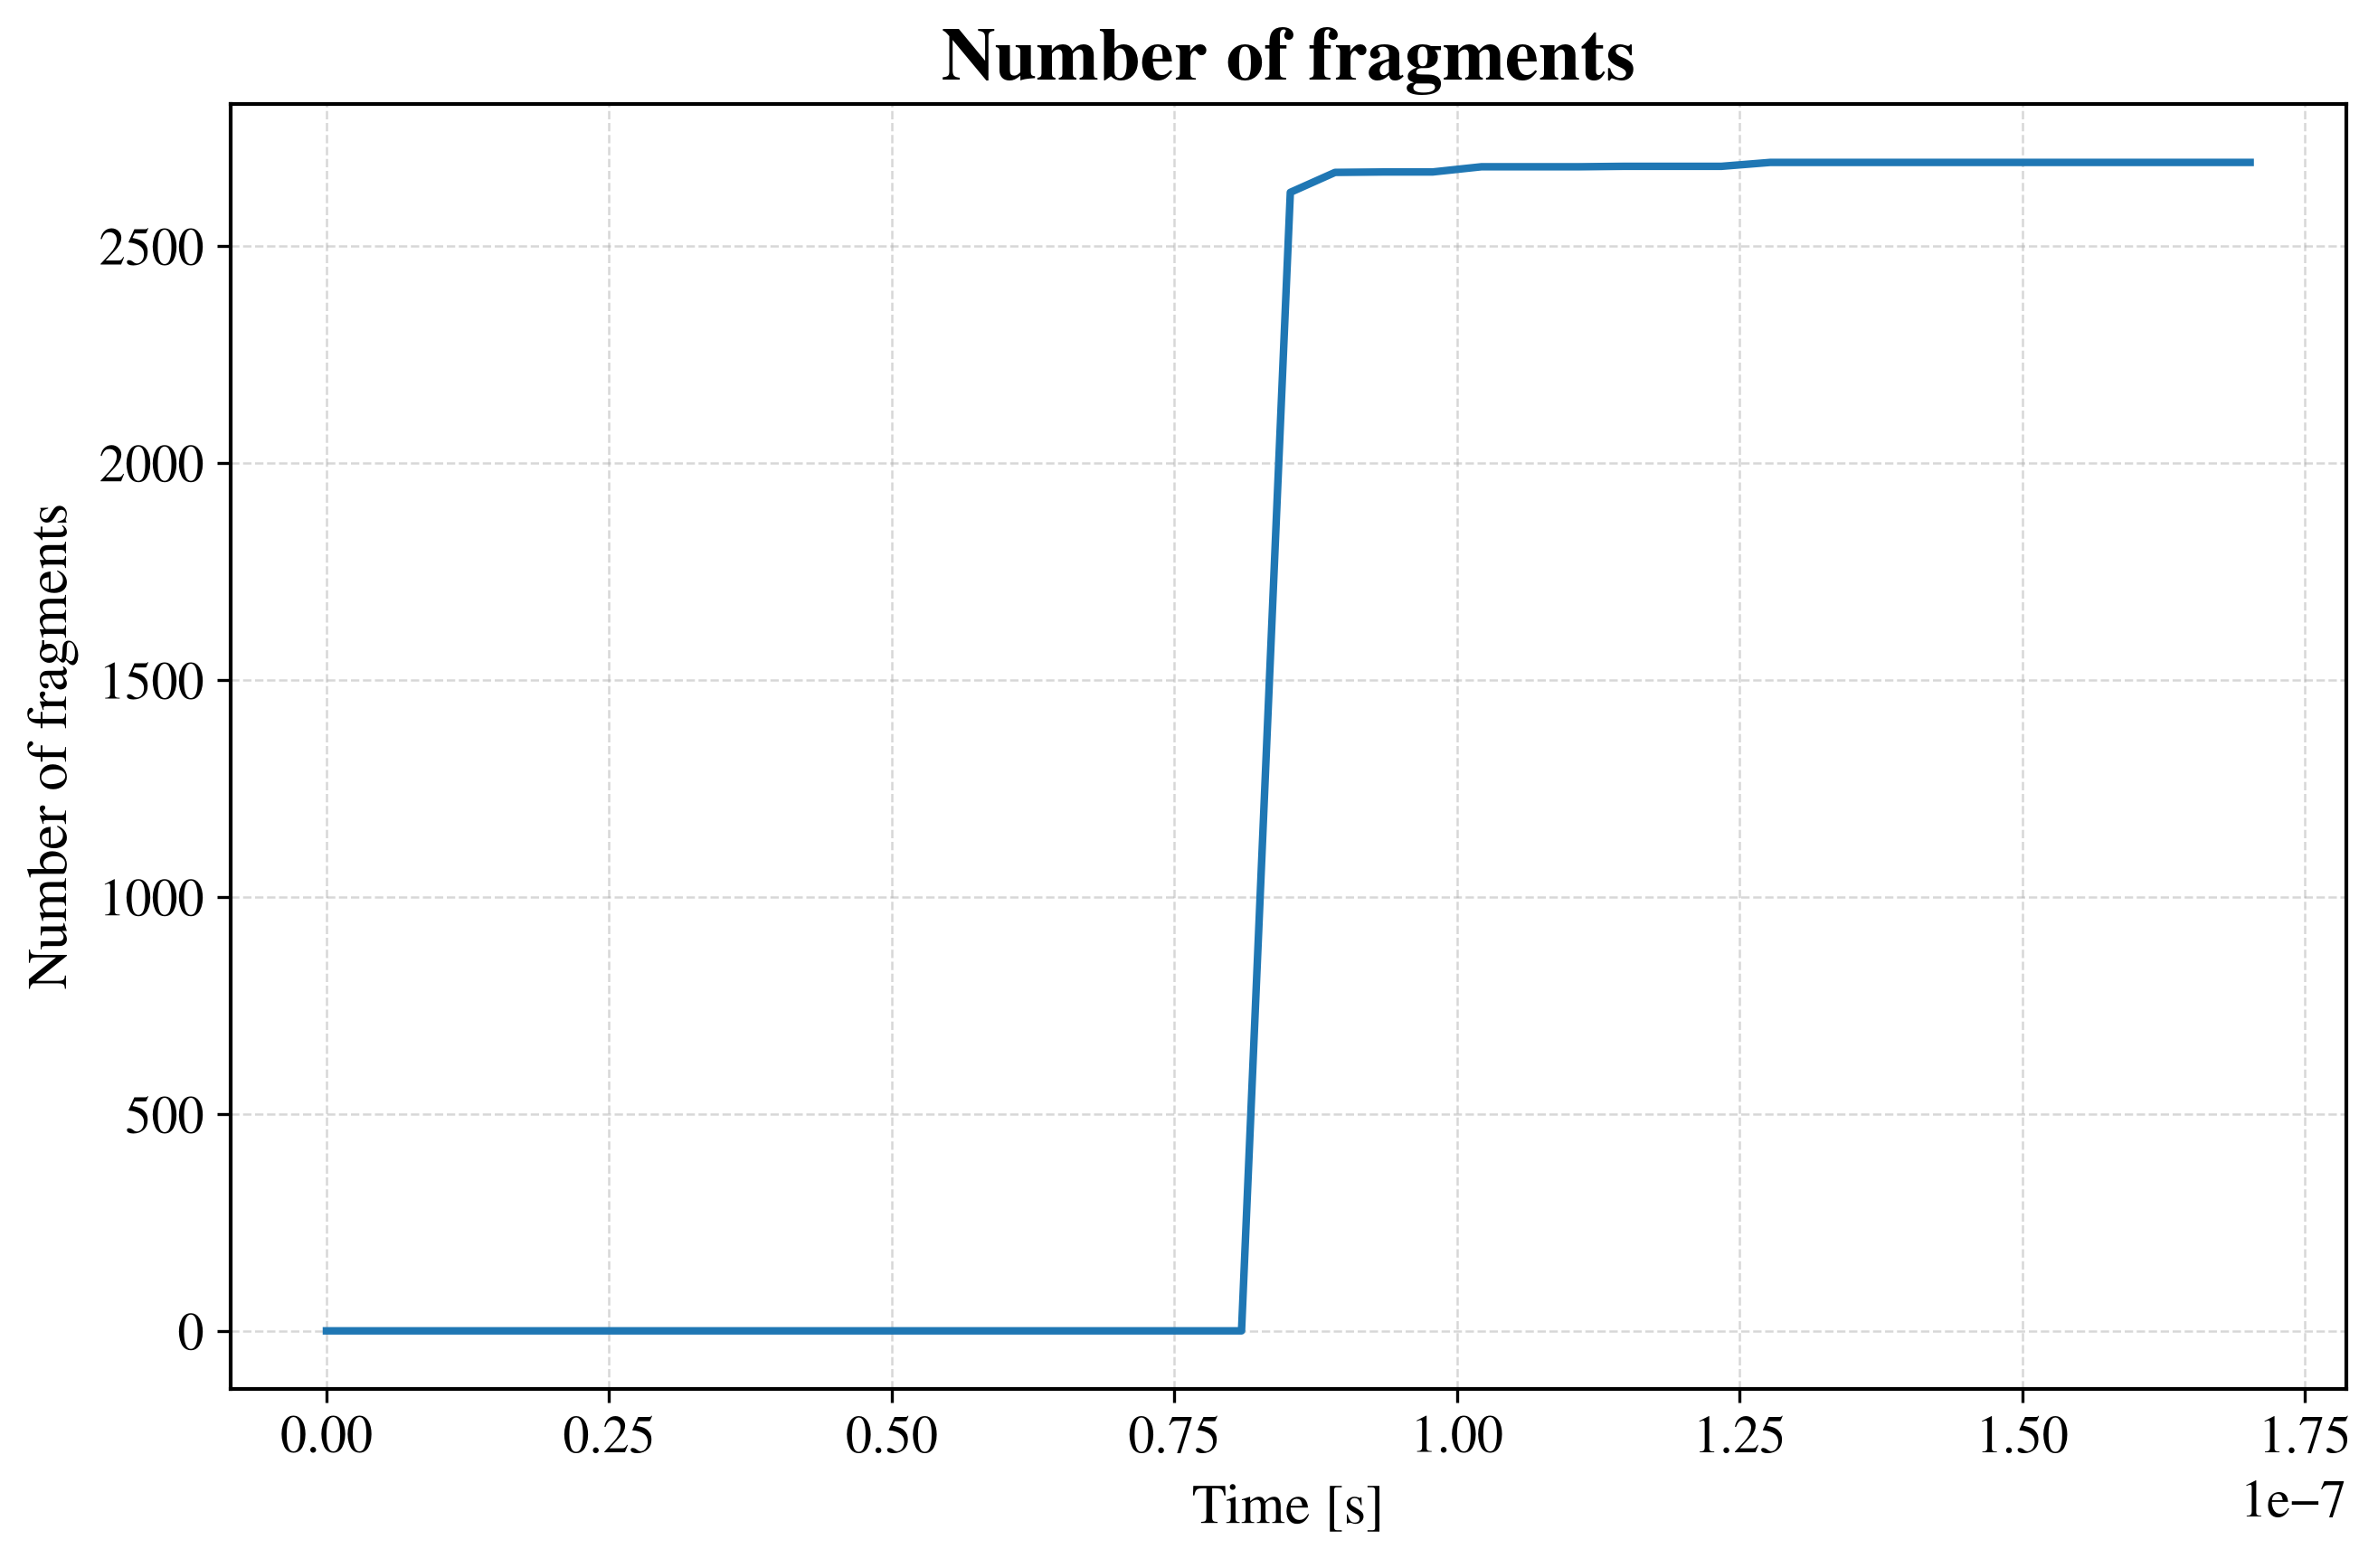

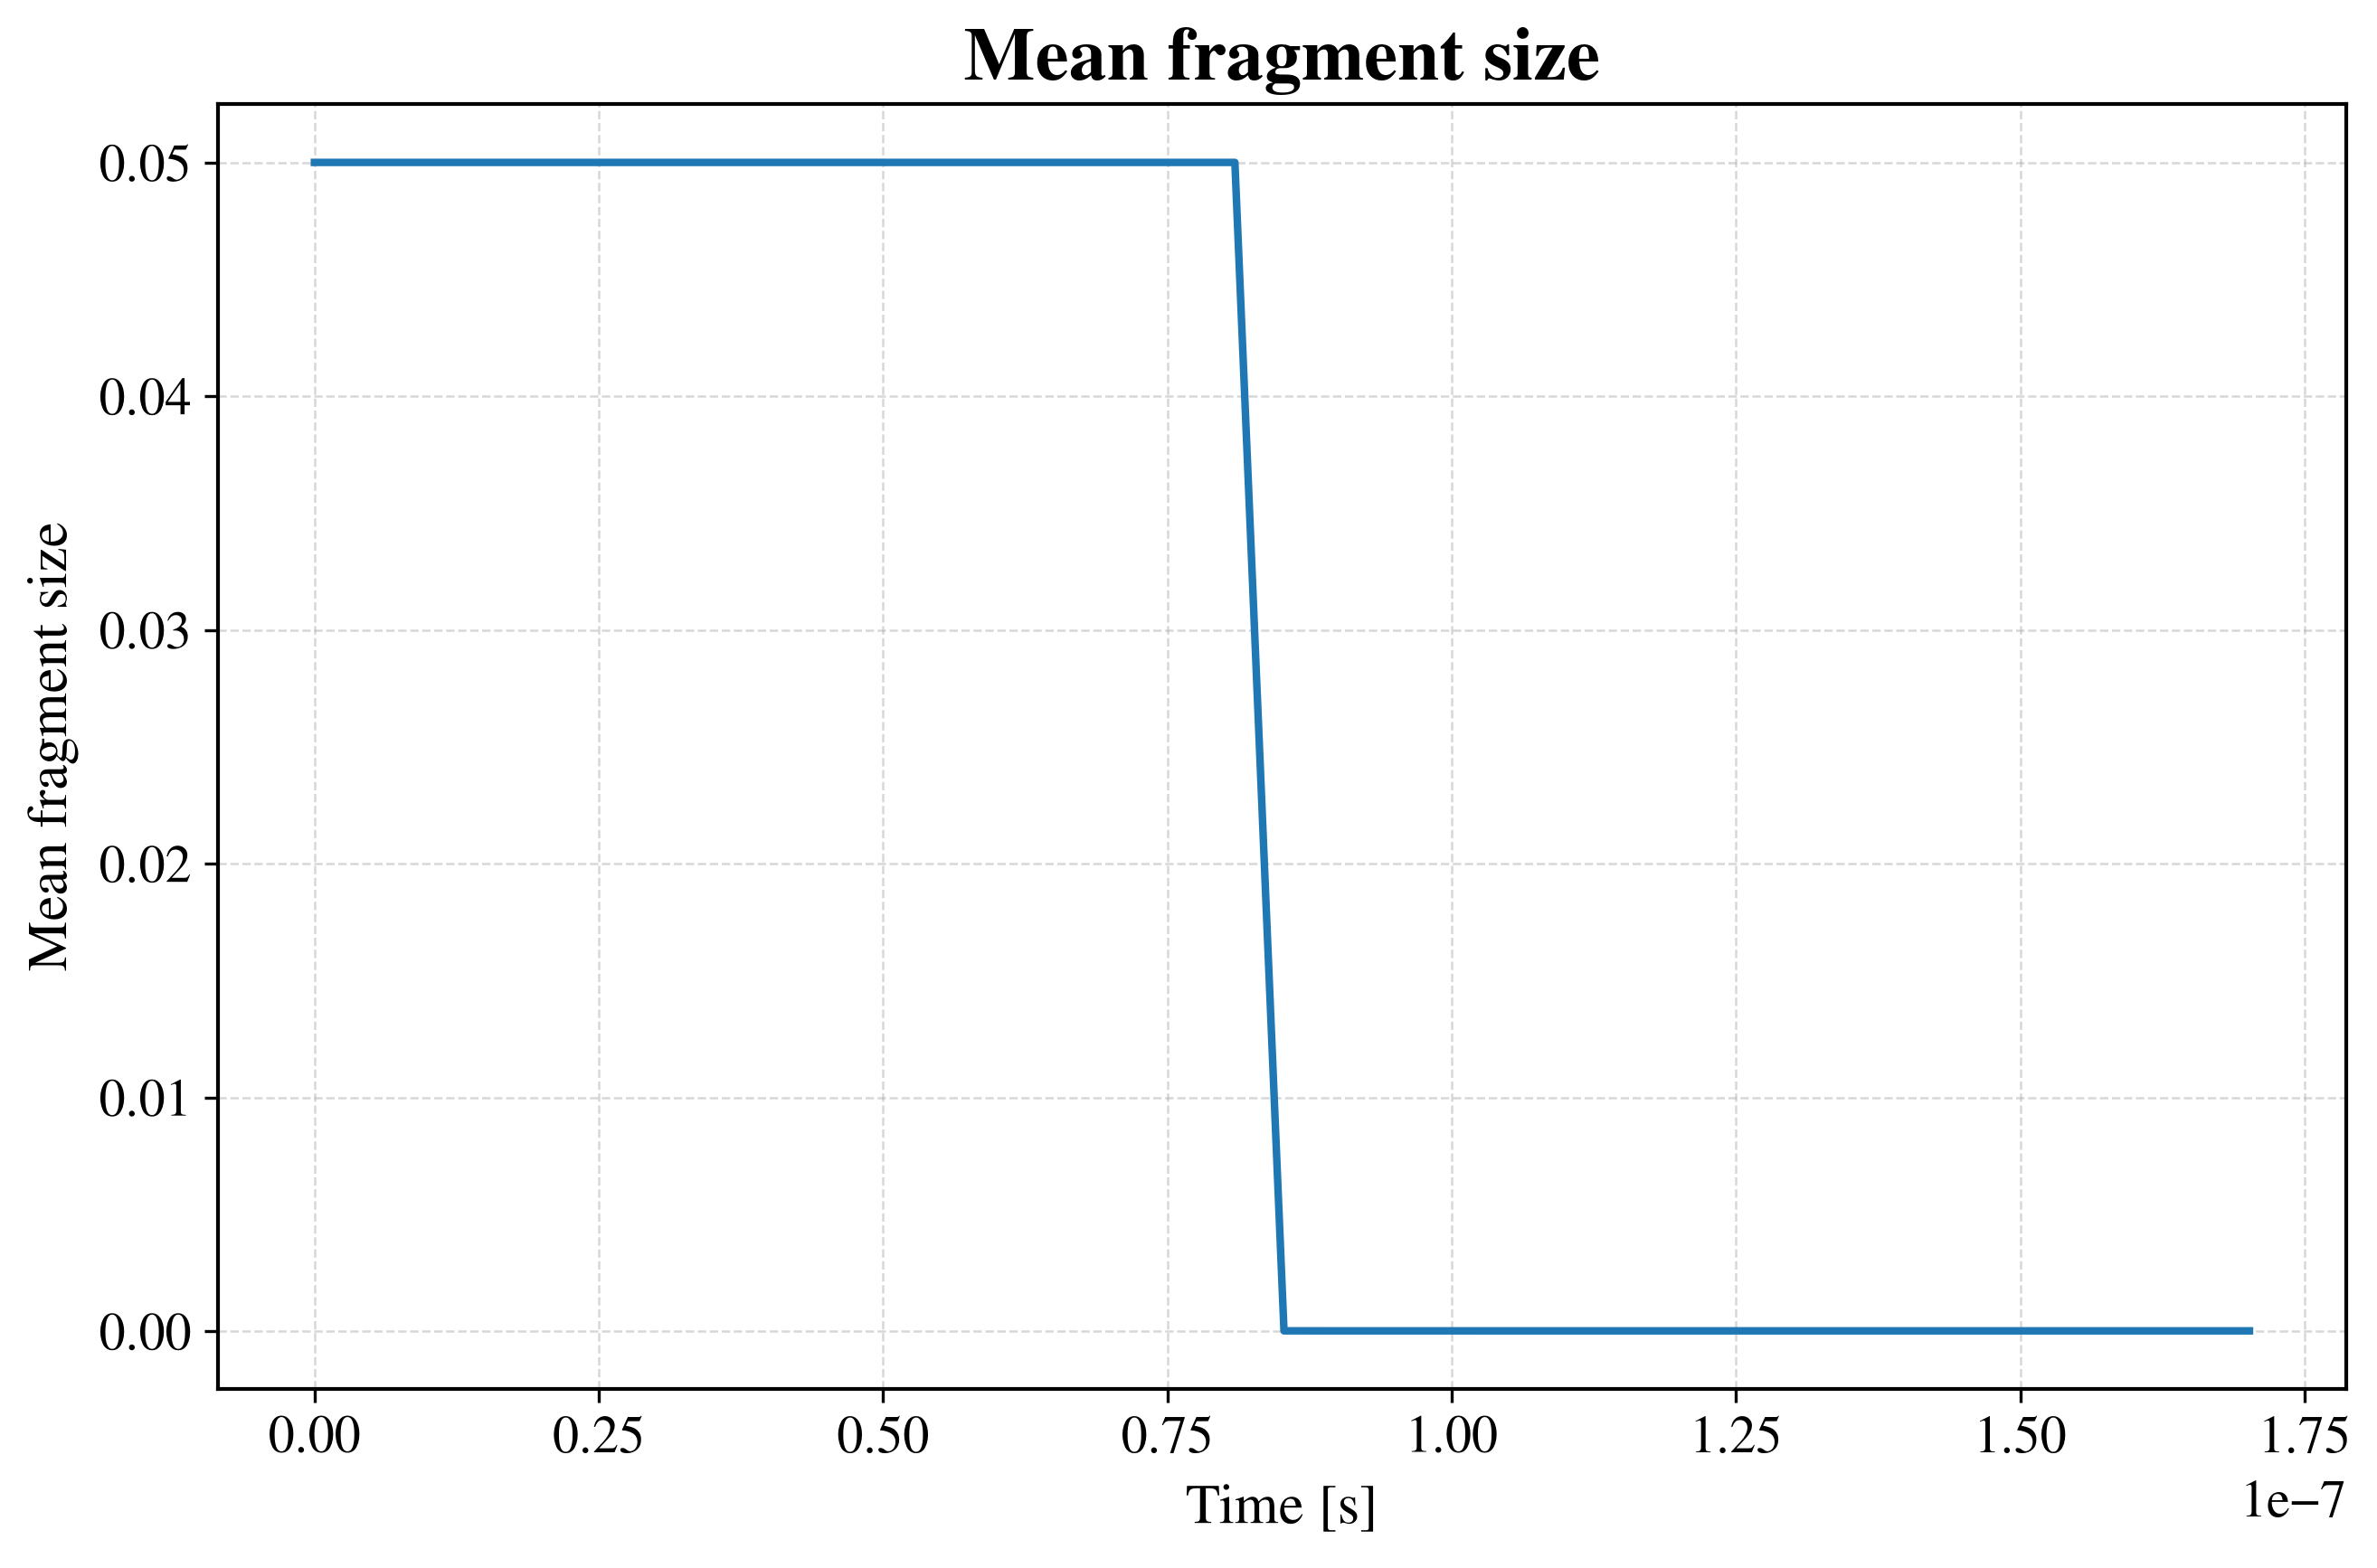

In [2]:
import numpy as np

data = np.loadtxt("data/PD/results.out", skiprows=1)

snapshot = data[:, 0]
time = data[:, 1]
kinetic = data[:, 2]
strain_energy = data[:, 3]
dissipated = data[:, 4]
external_work = data[:, 5]
num_fragments = data[:, 6]
mean_fragment_size = data[:, 7]

plots = {
    "Kinetic energy": kinetic,
    "Strain energy": strain_energy,
    "Dissipated energy": dissipated,
    "External work": external_work,
    "Number of fragments": num_fragments,
    "Mean fragment size": mean_fragment_size,
}

for name, values in plots.items():
    plt.figure(figsize=(9, 6))
    plt.plot(time, values)
    plt.title(name)
    plt.xlabel("Time [s]")
    plt.ylabel(name)
    plt.grid(True)
    plt.tight_layout()
    plt.show()